# Echo — Growth Modeling & Data-Driven Strategy (IMT 2026 final project)

**Board question: should Echo roll out aggressive push notifications to everyone?**

This notebook follows the course structure step by step:

| # | Section | Course concept used |
|---|---|---|
| 0 | Setup | – |
| 1 | Data exploration (raw extract) | – |
| 2 | Data cleaning + cleaning log | – |
| 3 | Funnel & growth loop: where does value leak? | AARRR funnel, growth loops, "aha moment" |
| 4 | Segments: compare like with like | Cohort analysis, activation |
| 5 | Unit economics: CAC, retention, LTV, payback | CAC, LTV, LTV:CAC, churn & retention |
| 6 | What changed during the 18 months? | Paid channel dynamics, cohort analysis |
| 7 | The A/B test: aggressive push vs control | Dark patterns & ethics of growth, vanity metrics |
| 8 | North Star Metric | NSM |
| 9 | Growth model: backtest + 3 scenarios | $U_{t+1} = U_t(1-churn) + New + Referrals$, what-if experiments |
| 10 | Next A/B test plan | Experimentation |
| 11 | Summary of findings | – |

Revenue convention: Echo earns **€9 per 1,000 ad impressions** (CPM), so each ad impression is worth €0.009. No cost data is given, so all LTVs are **gross ad revenue** (gross margin assumed to be 100 %, see caveats).

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from IPython.display import display, Markdown

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

DATA = Path('data')
OUT = Path('outputs'); FIG = OUT / 'figures'; CLEAN = OUT / 'clean'
for p in (FIG, CLEAN):
    p.mkdir(parents=True, exist_ok=True)

CPM = 9.0
REV_PER_AD = CPM / 1000                       # € per ad impression
EXTRACTION = pd.Timestamp('2026-06-30')       # data extracted on a Tuesday
LAST_FULL_WEEK = pd.Timestamp('2026-06-22')   # week of 2026-06-29 only has Mon+Tue -> partial
TEST_START, TEST_END = pd.Timestamp('2026-01-15'), pd.Timestamp('2026-03-15')
CHANNELS = ['organic_store', 'paid_social', 'podcast_cross_promo']

# Chart palette: reference categorical slots 1-4 (validated light mode: CVD dE >= 9.1,
# normal-vision dE >= 22.9). Aqua and yellow are below 3:1 contrast -> every chart is direct-labelled.
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
GRAY, INK, INK2, SURFACE = '#9a9994', '#0b0b0b', '#52514e', '#fcfcfb'
CH_COLORS = {'organic_store': BLUE, 'paid_social': ORANGE, 'podcast_cross_promo': AQUA}
AB_COLORS = {'control': BLUE, 'aggressive_push': ORANGE}
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])

plt.rcParams.update({
    'figure.figsize': (9, 4.2), 'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#d9d8d4',
    'axes.grid': True, 'grid.color': '#ecebe8', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'lines.linewidth': 2, 'legend.frameon': False,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE, 'savefig.bbox': 'tight',
})

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=150)

def end_label(ax, x, y, text):
    """Direct label at the end of a line (text in ink colour, never the series colour)."""
    ax.annotate(text, (x, y), xytext=(5, 0), textcoords='offset points', va='center', fontsize=9, color=INK2)

def end_labels(ax, x, items, min_gap_frac=0.05):
    """Several end-of-line labels, nudged vertically so they never overlap. items = [(y, text), ...]"""
    lo, hi = ax.get_ylim(); gap = (hi - lo) * min_gap_frac
    placed = []
    for y, text in sorted(items):
        y_txt = max(y, placed[-1] + gap) if placed else y
        placed.append(y_txt)
        ax.annotate(text, (x, y), xytext=(x, y_txt), textcoords='data', va='center', fontsize=9, color=INK2,
                    annotation_clip=False)

def pct(x, d=1):
    return f'{100 * x:.{d}f} %'

## 1. Data exploration (raw extract)

We read everything **as raw as possible** (user file as strings) so that no problem is silently hidden by pandas' type inference.

In [2]:
users_raw = pd.read_csv(DATA / 'users.csv', dtype=str)
weekly_raw = pd.read_csv(DATA / 'weekly_activity.csv', dtype={'user_id': str, 'week_start': str})
spend_raw = pd.read_csv(DATA / 'marketing_spend.csv', dtype={'month': str, 'channel': str})

for name, df in {'users.csv': users_raw, 'weekly_activity.csv': weekly_raw, 'marketing_spend.csv': spend_raw}.items():
    print(f'{name:22s} {df.shape[0]:>8,} rows x {df.shape[1]} cols')
print('Total rows:', f'{len(users_raw) + len(weekly_raw) + len(spend_raw):,}', '(data pack says 355,325)')

users.csv                20,909 rows x 7 cols
weekly_activity.csv     334,399 rows x 6 cols
marketing_spend.csv          17 rows x 3 cols
Total rows: 355,325 (data pack says 355,325)


In [3]:
def profile(df):
    return pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'missing': df.isna().sum(),
        'unique': df.nunique(),
        'example': df.iloc[0],
    })

display(users_raw.head())
display(profile(users_raw))
print('Exact duplicate rows:', users_raw.duplicated().sum(), '| duplicated user_id:', users_raw.user_id.duplicated().sum())

,user_id,signup_date,acquisition_channel,platform,age_bucket,push_variant,shows_followed_week1
0,U004452,2025-05-29,podcast_cross_promo,Android,35-44,standard,2
1,U006707,2025-08-09,paid_social,iOS,25-34,standard,2
2,U016164,2026-03-01,podcast_cross_promo,iOS,NaN,aggressive_push,1
3,U011607,2025-12-20,organic_store,Android,45+,standard,1
4,U001940,2025-03-14,paid_social,Android,25-34,standard,2


,dtype,missing,unique,example
user_id,object,0,20785,U004452
signup_date,object,0,780,2025-05-29
acquisition_channel,object,0,3,podcast_cross_promo
platform,object,0,2,Android
age_bucket,object,660,4,35-44
push_variant,object,0,6,standard
shows_followed_week1,object,0,12,2


Exact duplicate rows: 124 | duplicated user_id: 124


In [4]:
for col in ['acquisition_channel', 'platform', 'age_bucket', 'push_variant', 'shows_followed_week1']:
    print(f'--- {col}')
    print(users_raw[col].value_counts(dropna=False).to_string(), '\n')

--- acquisition_channel
acquisition_channel
paid_social            8950
organic_store          7722
podcast_cross_promo    4237 

--- platform
platform
Android    10496
iOS        10413 

--- age_bucket
age_bucket
25-34    7043
18-24    5964
35-44    4143
45+      3099
NaN       660 

--- push_variant
push_variant
standard           18181
control             1276
aggressive_push     1240
Control              100
AGGRESSIVE_PUSH       58
aggressive            54 

--- shows_followed_week1
shows_followed_week1
2     5293
1     5167
3     3956
0     2514
4     2229
5     1100
6      440
7      153
8       40
9       13
11       3
12       1 



Date formats in `signup_date` (digits replaced by 9 to reveal the patterns):

In [5]:
print(users_raw.signup_date.str.replace(r'\d', '9', regex=True).value_counts())
print('\nExamples of the minority format:', users_raw.loc[~users_raw.signup_date.str.match(r'^\d{4}-'), 'signup_date'].head(5).tolist())

signup_date
9999-99-99    20595
99/99/9999      314
Name: count, dtype: int64

Examples of the minority format: ['22/02/2025', '01/01/2026', '20/11/2025', '28/07/2025', '17/07/2025']


In [6]:
display(weekly_raw.head())
display(profile(weekly_raw))
print('Exact duplicate rows:', weekly_raw.duplicated().sum())
print('week_start formats:', weekly_raw.week_start.str.replace(r'\d', '9', regex=True).value_counts().to_dict())
display(weekly_raw.describe(percentiles=[.01, .5, .99, .999]).T)

,user_id,week_start,sessions,listening_minutes,ad_impressions,push_notifications_received
0,U014739,2026-06-08,1,21.400,3,25
1,U002742,2025-04-28,3,70.700,10,8
2,U015251,2026-04-13,3,59.100,9,41
3,U008670,2025-09-08,6,94.500,16,3
4,U004384,2025-07-28,5,81.900,14,3


,dtype,missing,unique,example
user_id,object,0,20785,U014739
week_start,object,0,79,2026-06-08
sessions,int64,0,18,1
listening_minutes,float64,0,3801,21.400
ad_impressions,int64,0,69,3
push_notifications_received,int64,0,55,25


Exact duplicate rows: 1663


week_start formats: {'9999-99-99': 334399}


,count,mean,std,min,1%,50%,99%,99.9%,max
sessions,"334,399.000",3.511,1.845,1.000,1.000,3.000,9.000,11.000,21.000
listening_minutes,"334,399.000",114.526,"1,737.446",-1.000,13.100,70.100,264.302,430.281,"99,999.000"
ad_impressions,"334,399.000",11.563,6.883,1.000,2.000,10.000,32.000,44.000,82.000
push_notifications_received,"334,399.000",5.255,6.231,0.000,0.000,4.000,36.000,44.000,58.000


`listening_minutes` has a minimum of −1 and a maximum of 99,999, far beyond the 99.9th percentile. Look at the extreme values:

In [7]:
lm = weekly_raw.listening_minutes
print('Values <= 0  :', lm[lm <= 0].value_counts().to_dict())
print('Values > 1000:', lm[lm > 1000].value_counts().to_dict())
print('Largest "normal" value:', lm[lm < 1000].max())
print('A week has 7 x 24 x 60 =', 7 * 24 * 60, 'minutes: 10,080 listening minutes means non-stop listening for a full week -> impossible')

Values <= 0  : {-1.0: 96}
Values > 1000: {10080.0: 105, 99999.0: 100}
Largest "normal" value: 827.8
A week has 7 x 24 x 60 = 10080 minutes: 10,080 listening minutes means non-stop listening for a full week -> impossible


In [8]:
display(spend_raw)
months = pd.to_datetime(spend_raw.month)
expected = pd.date_range('2025-01-01', '2026-06-01', freq='MS')
print('Missing months:', [d.strftime('%Y-%m') for d in expected.difference(months)])
print('Channels with spend:', spend_raw.channel.unique())

,month,channel,spend_eur
0,2025-01-01,paid_social,990.000
1,2025-02-01,paid_social,"1,020.000"
2,2025-03-01,paid_social,"1,050.000"
3,2025-04-01,paid_social,"1,080.000"
4,2025-06-01,paid_social,"1,150.000"
5,2025-07-01,paid_social,"1,180.000"
6,2025-08-01,paid_social,"1,220.000"
7,2025-09-01,paid_social,"1,250.000"
8,2025-10-01,paid_social,"1,290.000"
9,2025-11-01,paid_social,"1,330.000"


Missing months: ['2025-05']
Channels with spend: ['paid_social']


**First observations**

* `users.csv`: 124 exact duplicate rows, two date formats (ISO and `DD/MM/YYYY`), four spellings of the push variant, 660 missing age buckets.
* `weekly_activity.csv`: 1,663 exact duplicate rows; impossible listening values (−1, 10,080 = a full week non-stop, 99,999 = sentinel).
* `marketing_spend.csv`: only `paid_social` has spend, and **May 2025 is missing**.
* Data is extracted on Tuesday 30 June 2026, so the week starting 29 June 2026 is only 2 days long (partial week).

## 2. Data cleaning

Every rule is logged with the number of rows it affects. Checks that found nothing are logged too (rows affected = 0) because they prove the issue was looked for.

In [9]:
cleaning_log = []
def log(file, issue, rule, n):
    cleaning_log.append({'file': file, 'issue': issue, 'rule applied': rule, 'rows affected': int(n)})

### 2.1 users.csv

In [10]:
u = users_raw.copy()

# 1. exact duplicates
n = u.duplicated().sum(); u = u.drop_duplicates()
log('users.csv', 'Exact duplicate rows', 'Dropped, first occurrence kept', n)
n = u.user_id.duplicated().sum()
log('users.csv', 'Same user_id with conflicting attributes', 'Check only (none left after dedup)', n)
assert u.user_id.is_unique

# 2. mixed date formats
iso = pd.to_datetime(u.signup_date, format='%Y-%m-%d', errors='coerce')
alt = u.loc[iso.isna(), 'signup_date'].str.split('/', expand=True).astype(int)
print('DD/MM/YYYY rows:', len(alt), '| 1st part > 12:', (alt[0] > 12).sum(), '| 2nd part > 12:', (alt[1] > 12).sum(),
      '-> the first part is the day, so the format is day-first')
eu = pd.to_datetime(u.signup_date, format='%d/%m/%Y', errors='coerce')
u['signup_date'] = iso.fillna(eu)
assert u.signup_date.notna().all()
log('users.csv', 'Mixed date formats (DD/MM/YYYY next to ISO)', 'Parsed as day-first (validated: first part > 12 occurs, second never)', len(alt))
n = (~u.signup_date.between('2025-01-01', EXTRACTION)).sum()
log('users.csv', 'Signup date outside Jan 2025 - 30 Jun 2026', 'Check only', n)

# 3. inconsistent labels
before = u.push_variant.copy()
u['push_variant'] = u.push_variant.str.strip().str.lower().replace({'aggressive': 'aggressive_push'})
log('users.csv', "Inconsistent push_variant labels ('Control', 'AGGRESSIVE_PUSH', 'aggressive')", 'Lower-cased and mapped to control / aggressive_push', (before != u.push_variant).sum())
for col in ['acquisition_channel', 'platform']:
    log('users.csv', f'Inconsistent {col} labels', 'Check only (3 / 2 clean labels)', 0)

# 4. missing age
n = u.age_bucket.isna().sum(); u['age_bucket'] = u.age_bucket.fillna('unknown')
log('users.csv', 'Missing age_bucket', "Kept the users, label 'unknown' (dropping would bias channel/variant mix)", n)

# 5. numeric field
u['shows_followed_week1'] = u.shows_followed_week1.astype(int)
n = (~u.shows_followed_week1.between(0, 30)).sum()
log('users.csv', 'Impossible shows_followed_week1 (<0 or >30)', 'Check only (range is 0-12)', n)

# 6. experiment integrity: variants must exist only for signups inside 15 Jan - 15 Mar 2026
in_window = u.signup_date.between(TEST_START, TEST_END)
bad = ((u.push_variant != 'standard') & ~in_window) | ((u.push_variant == 'standard') & in_window)
log('users.csv', 'push_variant inconsistent with the test window', 'Check only: every in-window signup is in the test, none outside', bad.sum())

# 7. internal / test accounts: id pattern
n = (~u.user_id.str.match(r'^U\d{6}$')).sum()
log('users.csv', 'Internal/test account: user_id not of the form U + 6 digits', 'Check only', n)
print(u.push_variant.value_counts())

DD/MM/YYYY rows: 311 | 1st part > 12: 191 | 2nd part > 12: 0 -> the first part is the day, so the format is day-first


push_variant
standard           18076
control             1366
aggressive_push     1343
Name: count, dtype: int64


### 2.2 weekly_activity.csv

In [11]:
w = weekly_raw.copy()

n = w.duplicated().sum(); w = w.drop_duplicates()
log('weekly_activity.csv', 'Exact duplicate rows', 'Dropped, first occurrence kept', n)
n = w.duplicated(['user_id', 'week_start']).sum()
log('weekly_activity.csv', 'Two different rows for the same user-week', 'Check only', n)

w['week_start'] = pd.to_datetime(w.week_start, format='%Y-%m-%d')
log('weekly_activity.csv', 'week_start not a Monday', 'Check only', (w.week_start.dt.dayofweek != 0).sum())

lm = w.listening_minutes
rules = {
    'Negative listening_minutes (-1)': lm < 0,
    'listening_minutes = 10,080 (7x24x60: a full week non-stop, impossible)': lm == 10080,
    'listening_minutes = 99,999 (sentinel / placeholder value)': lm == 99999,
}
bad_minutes = pd.Series(False, index=w.index)
for issue, mask in rules.items():
    log('weekly_activity.csv', issue, 'Set to NaN, then imputed from ad_impressions (rule below)', mask.sum())
    bad_minutes |= mask
print('Rows with bad minutes:', bad_minutes.sum(), '| other values above 600 min/week:', ((lm > 600) & ~bad_minutes).sum())

# Imputation: ads are served at a very stable rate per listening hour (see distribution), so minutes ~ ads / rate
ok = ~bad_minutes
ads_per_hour = w.loc[ok, 'ad_impressions'] / w.loc[ok, 'listening_minutes'] * 60
print('Ads per listening hour on clean rows:', ads_per_hour.describe(percentiles=[.01, .5, .99]).round(2).to_dict())
ADS_PER_HOUR = ads_per_hour.median()
w['minutes_imputed'] = bad_minutes
w['minutes'] = w.listening_minutes.where(ok, w.ad_impressions / ADS_PER_HOUR * 60)
log('weekly_activity.csv', 'Imputation of the NaN listening minutes', f'minutes = ad_impressions / {ADS_PER_HOUR:.2f} ads per hour x 60 (flag column minutes_imputed)', bad_minutes.sum())

# referential integrity and time coherence
log('weekly_activity.csv', 'user_id not present in users.csv (orphans)', 'Check only', (~w.user_id.isin(u.user_id)).sum())
tmp = w.merge(u[['user_id', 'signup_date']], on='user_id')
signup_week = tmp.signup_date - pd.to_timedelta(tmp.signup_date.dt.dayofweek, unit='D')
log('weekly_activity.csv', 'Activity before the signup week', 'Check only', (tmp.week_start < signup_week).sum())
log('weekly_activity.csv', 'Activity after the extraction date', 'Check only', (w.week_start > EXTRACTION).sum())
for col in ['sessions', 'ad_impressions', 'push_notifications_received']:
    log('weekly_activity.csv', f'Negative or missing {col}', 'Check only', ((w[col] < 0) | w[col].isna()).sum())

w['partial_week'] = w.week_start > LAST_FULL_WEEK
log('weekly_activity.csv', 'Partial last week (29-30 June 2026, extraction on a Tuesday)', 'Rows kept, but excluded from weekly KPIs and retention', w.partial_week.sum())

# gaps in tracking: weeks with no rows at all
all_weeks = pd.date_range(w.week_start.min(), w.week_start.max(), freq='W-MON')
log('weekly_activity.csv', 'Tracking gaps (weeks with no activity rows)', 'Check only', len(all_weeks.difference(w.week_start.unique())))

Rows with bad minutes: 300 | other values above 600 min/week: 6
Ads per listening hour on clean rows: {'count': 332436.0, 'mean': 8.79, 'std': 1.51, 'min': 5.46, '1%': 6.23, '50%': 8.57, '99%': 13.52, 'max': 22.76}


**Internal / test accounts.** The data pack warns about them, so we look for behavioural fingerprints: users with no activity, activity before signup (checked above), bot-like constant usage, or impossible intensities.

In [12]:
per_user = w.groupby('user_id').agg(weeks=('week_start', 'count'), sess_std=('sessions', 'std'),
                                     min_std=('minutes', 'std'), max_sessions=('sessions', 'max'))
checks = {
    'Users with no activity row at all': (~u.user_id.isin(w.user_id)).sum(),
    'Bot-like: >= 8 active weeks with constant sessions AND minutes': ((per_user.weeks >= 8) & (per_user.sess_std == 0) & (per_user.min_std == 0)).sum(),
    'More than 50 sessions in one week': (per_user.max_sessions > 50).sum(),
    'Ads per listening hour outside 3-30 (ad server anomaly)': (~ads_per_hour.between(3, 30)).sum(),
}
for k, v in checks.items():
    print(f'{k:65s} {v}')
    log('users.csv / weekly', f'Internal/test account signal: {k}', 'Check only', v)
print('\n-> No internal/test account fingerprint found in this extract: no user removed on this ground.')

Users with no activity row at all                                 0
Bot-like: >= 8 active weeks with constant sessions AND minutes    0
More than 50 sessions in one week                                 0
Ads per listening hour outside 3-30 (ad server anomaly)           0

-> No internal/test account fingerprint found in this extract: no user removed on this ground.


### 2.3 marketing_spend.csv

In [13]:
s = spend_raw.copy()
s['month'] = pd.to_datetime(s.month)
s = s.set_index('month').reindex(pd.date_range('2025-01-01', '2026-06-01', freq='MS'))
s.index.name = 'month'
s['channel'] = 'paid_social'
s['spend_imputed'] = s.spend_eur.isna()
s['spend_eur'] = s.spend_eur.interpolate()
log('marketing_spend.csv', 'Missing month (2025-05)', 'Linear interpolation between April and June (cross-checked with CAC below)', s.spend_imputed.sum())
log('marketing_spend.csv', 'Only paid_social has spend', 'Assumption: organic_store and podcast_cross_promo cost EUR 0 (no data); flagged as a caveat', 0)

# cross-check: CAC = spend / paid signups is almost constant, so the imputed value must give the same CAC
paid_signups = u[u.acquisition_channel == 'paid_social'].groupby(u.signup_date.dt.to_period('M').dt.to_timestamp()).size()
s['paid_signups'] = paid_signups
s['cac_paid'] = s.spend_eur / s.paid_signups
display(s.loc['2025-03':'2025-07'])
print(f"Implied May spend from the median CAC: EUR {s.cac_paid.median() * s.loc['2025-05-01', 'paid_signups']:.0f} (interpolated: EUR {s.loc['2025-05-01', 'spend_eur']:.0f})")
spend = s.reset_index()

,channel,spend_eur,spend_imputed,paid_signups,cac_paid
month,,,,,
2025-03-01,paid_social,"1,050.000",False,403,2.605
2025-04-01,paid_social,"1,080.000",False,415,2.602
2025-05-01,paid_social,"1,115.000",True,427,2.611
2025-06-01,paid_social,"1,150.000",False,440,2.614
2025-07-01,paid_social,"1,180.000",False,453,2.605


Implied May spend from the median CAC: EUR 1112 (interpolated: EUR 1115)


### 2.4 Cleaning log and clean files

In [14]:
clog = pd.DataFrame(cleaning_log)
clog.to_csv(OUT / 'cleaning_log.csv', index=False)
pd.set_option('display.max_colwidth', 120)
display(clog)
print(f'users: {len(users_raw):,} -> {len(u):,} rows | weekly: {len(weekly_raw):,} -> {len(w):,} rows | spend: {len(spend_raw)} -> {len(spend)} rows')

,file,issue,rule applied,rows affected
0,users.csv,Exact duplicate rows,"Dropped, first occurrence kept",124
1,users.csv,Same user_id with conflicting attributes,Check only (none left after dedup),0
2,users.csv,Mixed date formats (DD/MM/YYYY next to ISO),"Parsed as day-first (validated: first part > 12 occurs, second never)",311
3,users.csv,Signup date outside Jan 2025 - 30 Jun 2026,Check only,0
4,users.csv,"Inconsistent push_variant labels ('Control', 'AGGRESSIVE_PUSH', 'aggressive')",Lower-cased and mapped to control / aggressive_push,211
5,users.csv,Inconsistent acquisition_channel labels,Check only (3 / 2 clean labels),0
6,users.csv,Inconsistent platform labels,Check only (3 / 2 clean labels),0
7,users.csv,Missing age_bucket,"Kept the users, label 'unknown' (dropping would bias channel/variant mix)",657
8,users.csv,Impossible shows_followed_week1 (<0 or >30),Check only (range is 0-12),0
9,users.csv,push_variant inconsistent with the test window,"Check only: every in-window signup is in the test, none outside",0


users: 20,909 -> 20,785 rows | weekly: 334,399 -> 332,736 rows | spend: 17 -> 18 rows


In [15]:
# derived fields used everywhere below
u['signup_week'] = u.signup_date - pd.to_timedelta(u.signup_date.dt.dayofweek, unit='D')
u['signup_month'] = u.signup_date.dt.to_period('M').dt.to_timestamp()
u['activated'] = u.shows_followed_week1 >= 3          # "aha moment", justified in section 3
u['max_age_obs'] = (LAST_FULL_WEEK - u.signup_week).dt.days // 7   # last week-of-life we can observe

w = w.merge(u[['user_id', 'signup_week', 'signup_month', 'acquisition_channel', 'platform', 'age_bucket',
               'push_variant', 'shows_followed_week1', 'activated']], on='user_id', how='left')
w['age_wk'] = (w.week_start - w.signup_week).dt.days // 7   # 0 = signup week
w['revenue'] = w.ad_impressions * REV_PER_AD
wf = w[~w.partial_week].copy()                               # full weeks only

u.to_csv(CLEAN / 'users_clean.csv', index=False)
w.to_csv(CLEAN / 'weekly_activity_clean.csv', index=False)
spend.to_csv(CLEAN / 'marketing_spend_clean.csv', index=False)
print('Clean files written to', CLEAN)

Clean files written to outputs/clean


### 2.5 Analysis helpers

**Retention definition.** A user is *active in week k of life* if they have an activity row in the k-th week after their signup week (week 0 = signup week). Because users signed up at different dates, at week k we only count users we can actually observe that far (signup week + k ≤ 22 June 2026). This avoids the classic right-censoring bias of recent cohorts.

**Value curve.** For a group of users, `v(k)` = ad revenue earned in week k of life divided by the number of users observable at k. Summing `v(k)` gives the expected revenue per acquired user, which is the LTV. Beyond the observed horizon the active share is extrapolated with an exponential decay fitted on the last observed weeks.

In [16]:
def value_curves(us, wdf=None, last_week=LAST_FULL_WEEK, min_n=150):
    """Per week of life k: n observable, share active S, revenue per acquired user v, revenue per active r, etc."""
    wdf = wf if wdf is None else wdf
    max_age = ((last_week - us.signup_week).dt.days // 7).clip(lower=0).values
    counts = np.bincount(max_age)
    n_obs = counts[::-1].cumsum()[::-1]                     # n_obs[k] = #users with max_age >= k
    a = (wdf[wdf.user_id.isin(us.user_id) & (wdf.week_start <= last_week)]
         .groupby('age_wk').agg(active=('user_id', 'nunique'), rev=('revenue', 'sum'), sess=('sessions', 'sum'),
                                mins=('minutes', 'sum'), ads=('ad_impressions', 'sum'), push=('push_notifications_received', 'sum')))
    df = a.reindex(range(len(n_obs)), fill_value=0)
    df['n_obs'] = n_obs
    df = df[df.n_obs >= min_n].copy()
    df['S'] = df.active / df.n_obs
    for c in ['rev', 'sess', 'mins', 'ads', 'push']:
        df[c + '_per_user'] = df[c] / df.n_obs
    df['v'] = df.rev_per_user
    df['r'] = df.rev / df.active.replace(0, np.nan)
    return df


def extend(vc, horizon=160, fit_weeks=26):
    """Extend S and v beyond the observed horizon with an exponential decay fitted on the last `fit_weeks` weeks."""
    K = vc.index.max()
    fit = vc[vc.index >= max(4, K - fit_weeks)]
    slope, intercept = np.polyfit(fit.index, np.log(fit.S.clip(lower=1e-4)), 1)
    slope = min(slope, -0.003)                               # never assume retention grows again
    anchor = np.exp(intercept + slope * K)                   # smoothed value at K
    r_late = (fit.rev.sum() / fit.active.sum())
    idx = np.arange(horizon)
    S = pd.Series(np.nan, index=idx); v = pd.Series(np.nan, index=idx)
    obs = idx[idx <= K]
    S[obs] = vc.S.reindex(obs).values; v[obs] = vc.v.reindex(obs).values
    tail = idx[idx > K]
    S[tail] = anchor * np.exp(slope * (tail - K)); v[tail] = S[tail] * r_late
    return pd.DataFrame({'S': S, 'v': v, 'observed': idx <= K})


act_sets = wf.groupby('age_wk').user_id.apply(set)
def active_at(ids, k):
    return ids.isin(act_sets.get(k, set()))

STD = u[u.push_variant != 'aggressive_push']   # users with the normal notification experience (standard + control)
print('Users with the normal push experience:', len(STD), '| aggressive arm:', (u.push_variant == 'aggressive_push').sum())

Users with the normal push experience: 19442 | aggressive arm: 1343


## 3. Funnel and growth loop: where does value leak?

### 3.1 The AARRR funnel of Echo

| AARRR stage | What it is at Echo | Metric available in the data |
|---|---|---|
| Acquisition | install + account (3 channels) | signups, CAC (paid_social only) |
| Activation | user follows shows in week 1 (the "aha moment" = having enough content to come back for) | `shows_followed_week1` |
| Retention | user keeps listening week after week | active in week k |
| Referral | no referral data; podcast cross-promotion plays this role | signups from `podcast_cross_promo` |
| Revenue | audio ads heard while listening, €9 CPM | `ad_impressions` × €0.009 |

To read the funnel on comparable users we take every **standard** user observable for at least 26 weeks (signed up before ~20 Dec 2025).

In [17]:
fc = u[(u.max_age_obs >= 26) & (u.push_variant == 'standard')].copy()
for k in [4, 12, 26]:
    fc[f'w{k}'] = active_at(fc.user_id, k)
steps = {
    'Signed up': np.ones(len(fc), bool),
    'Followed >= 1 show (week 1)': fc.shows_followed_week1 >= 1,
    'Followed >= 3 shows (week 1)': fc.activated,
    'Active in week 4': fc.w4,
    'Active in week 12': fc.w12,
    'Active in week 26': fc.w26,
}
funnel = pd.DataFrame({name: pd.Series(m, index=fc.index).groupby(fc.acquisition_channel).mean() for name, m in steps.items()}).T
funnel['all users'] = [pd.Series(m, index=fc.index).mean() for m in steps.values()]
print(f'Funnel cohort: {len(fc):,} standard users signed up {fc.signup_date.min():%d %b %Y} - {fc.signup_date.max():%d %b %Y}')
display((funnel * 100).round(1))

Funnel cohort: 12,148 standard users signed up 01 Jan 2025 - 28 Dec 2025


acquisition_channel,organic_store,paid_social,podcast_cross_promo,all users
Signed up,100.000,100.000,100.000,100.000
Followed >= 1 show (week 1),92.600,81.800,92.400,87.800
Followed >= 3 shows (week 1),48.700,25.400,46.200,38.000
Active in week 4,83.600,71.000,86.800,78.700
Active in week 12,58.600,37.400,66.300,50.800
Active in week 26,40.400,19.200,48.600,32.700


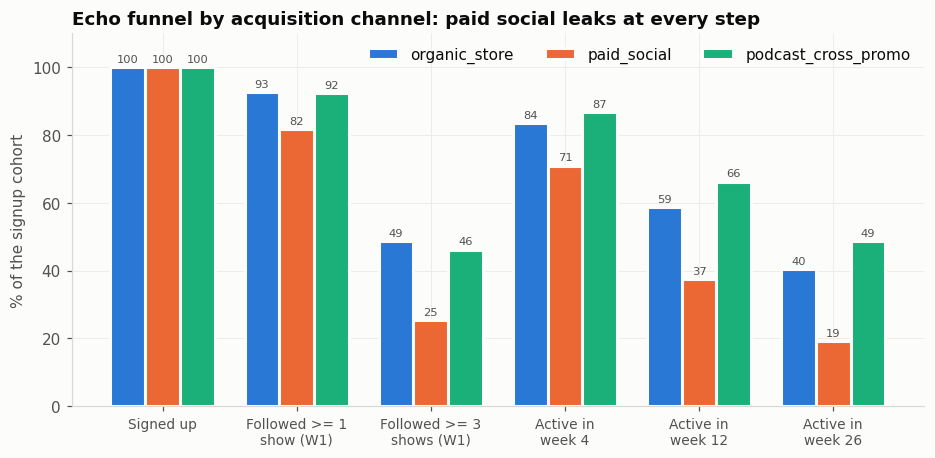

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(funnel)); bw = 0.26
for i, ch in enumerate(CHANNELS):
    bars = ax.bar(x + (i - 1) * bw, funnel[ch] * 100, bw, color=CH_COLORS[ch], label=ch, edgecolor=SURFACE, linewidth=2)
    ax.bar_label(bars, fmt='%.0f', fontsize=7.5, color=INK2, padding=2)
ax.set_xticks(x, ['Signed up', 'Followed >= 1\nshow (W1)', 'Followed >= 3\nshows (W1)', 'Active in\nweek 4', 'Active in\nweek 12', 'Active in\nweek 26'], fontsize=9)
ax.set_ylabel('% of the signup cohort'); ax.set_ylim(0, 110)
ax.set_title('Echo funnel by acquisition channel: paid social leaks at every step')
ax.legend(ncol=3, loc='upper right')
save(fig, '03_funnel_by_channel'); plt.show()

### 3.2 The "aha moment": how many shows must a user follow in week 1?

,users,W4,W12
shows,,,
0,1832,72.500,40.000
1,3733,73.500,41.700
2,3862,75.200,44.000
3,2857,85.600,63.900
4,1619,86.800,65.000
5,817,85.900,64.700
6,306,92.200,72.200
7,166,85.500,66.900


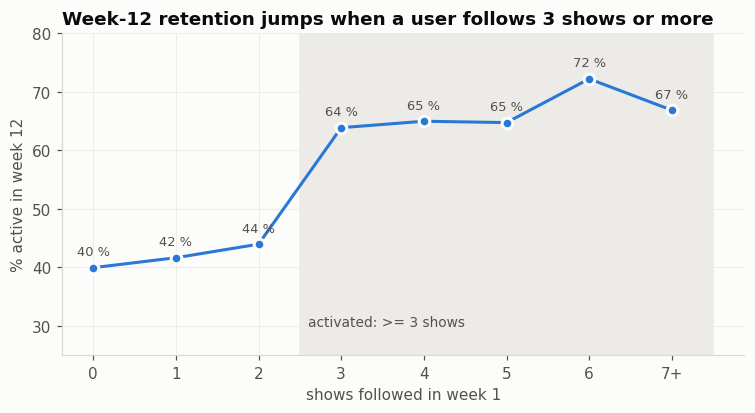

In [19]:
ret_by_shows = (STD[STD.max_age_obs >= 12]
                .assign(shows=lambda d: d.shows_followed_week1.clip(upper=7),
                        w4=lambda d: active_at(d.user_id, 4), w12=lambda d: active_at(d.user_id, 12))
                .groupby('shows').agg(users=('user_id', 'size'), W4=('w4', 'mean'), W12=('w12', 'mean')))
display(ret_by_shows.assign(W4=lambda d: (d.W4 * 100).round(1), W12=lambda d: (d.W12 * 100).round(1)))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(ret_by_shows.index, ret_by_shows.W12 * 100, color=BLUE, marker='o', markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
for k, v in ret_by_shows.W12.items():
    ax.annotate(f'{v*100:.0f} %', (k, v * 100), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=8.5, color=INK2)
ax.axvspan(2.5, 7.5, color='#ecebe8', zorder=0)
ax.text(2.6, 30, 'activated: >= 3 shows', fontsize=9, color=INK2)
ax.set_xticks(ret_by_shows.index, [str(i) if i < 7 else '7+' for i in ret_by_shows.index])
ax.set_xlabel('shows followed in week 1'); ax.set_ylabel('% active in week 12'); ax.set_ylim(25, 80)
ax.set_title('Week-12 retention jumps when a user follows 3 shows or more')
save(fig, '03_aha_moment'); plt.show()

The relationship is not linear: following 0, 1 or 2 shows gives about the same week-12 retention (~40-44 %), and **the step happens between 2 and 3 shows** (~64 %), after which it flattens. This is a textbook "aha moment": **activation = following at least 3 shows in week 1**.

In [20]:
act_share = STD.groupby('acquisition_channel').activated.mean()
print('Share of users activated (>= 3 shows in week 1):'); print(act_share.map(lambda x: f'{x:.1%}').to_string())
print(f'All channels: {STD.activated.mean():.1%}')

Share of users activated (>= 3 shows in week 1):
acquisition_channel
organic_store          48.1%
paid_social            25.1%
podcast_cross_promo    46.1%
All channels: 37.8%


### 3.3 Where is the value? (revenue concentration)

In [21]:
life_rev = wf[wf.user_id.isin(fc.user_id)].groupby('user_id').revenue.sum().reindex(fc.user_id).fillna(0).sort_values(ascending=False)
top20 = life_rev.iloc[:int(0.2 * len(life_rev))].sum() / life_rev.sum()
rev_w26 = life_rev[fc.set_index('user_id').w26].sum() / life_rev.sum()
print(f'Top 20 % of users generate {top20:.0%} of the ad revenue of the cohort')
print(f'Users still active in week 26 ({fc.w26.mean():.0%} of the cohort) generate {rev_w26:.0%} of its revenue')
print(f'Users not activated (< 3 shows) are {1 - fc.activated.mean():.0%} of signups but generate {life_rev[~fc.set_index("user_id").activated].sum() / life_rev.sum():.0%} of revenue')

Top 20 % of users generate 51% of the ad revenue of the cohort
Users still active in week 26 (33% of the cohort) generate 70% of its revenue
Users not activated (< 3 shows) are 62% of signups but generate 50% of revenue


### 3.4 The growth loop

Echo is a **retention-driven content loop**, financed by a (linear) paid funnel:

```
            ┌──────────────────────────────────────────────────────────────┐
            │                                                              │
  [Signup] ─► follows shows (W1) ─► new episodes ─► push "new episode" ─► session
     ▲                                                                      │
     │                                                                      ▼
     │        reinvest (paid_social)  ◄── ad revenue (€9 CPM) ◄── listening minutes ◄┘
     │                                                                      │
     └──── podcast cross-promo (shows promote Echo to their audience) ◄─────┘
```

* **Value** for the user = listening to the shows they follow. **Input** = followed shows; **output** = listening minutes, which produce ad revenue and keep the user in the loop.
* The push notification is the *trigger* of the loop. A *relevant* trigger ("new episode of a show you follow") feeds the loop; an *irrelevant* trigger ("Don't miss out!" five times a day) creates sessions without listening, and burns the trigger (users mute or leave). Section 7 tests this.
* The acquisition side is mostly a **funnel** (paid_social needs continuous spend) plus a weak acquisition loop through podcast cross-promotion. No invite data exists, so the K-factor cannot be measured.

**Where value leaks:**
1. **Activation**: only 38 % of users follow 3+ shows in week 1 (25 % on paid_social). Users who never reach it are 62 % of signups but bring only half of the revenue, and the top 20 % of users bring 51 % of it.
2. **Early retention (weeks 1-8)**, especially for paid_social.
3. **Paid social** brings the most users but the least valuable ones (section 5).

## 4. Segments: do the differences survive when we compare like with like?

### 4.1 Retention curves by channel (normal push experience)

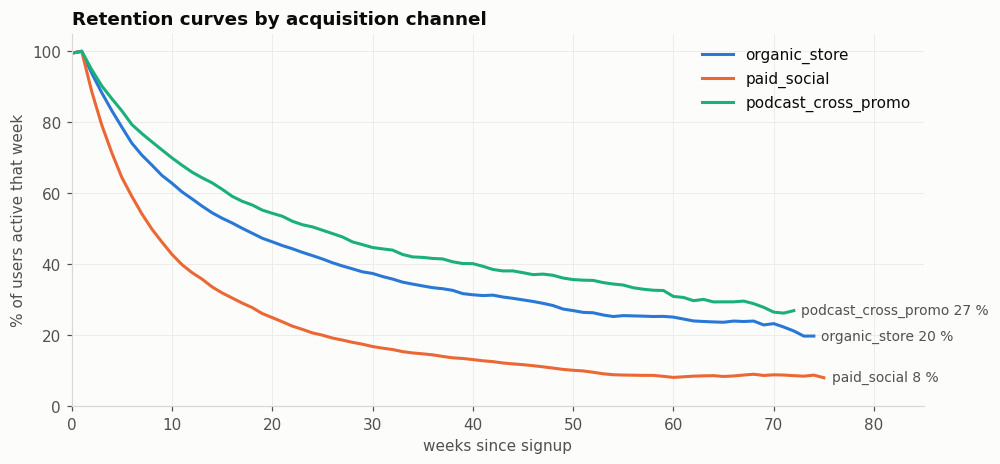

In [22]:
vc_ch = {ch: value_curves(STD[STD.acquisition_channel == ch], min_n=200) for ch in CHANNELS}
fig, ax = plt.subplots(figsize=(10, 4.4))
for ch, vc in vc_ch.items():
    ax.plot(vc.index, vc.S * 100, color=CH_COLORS[ch], label=ch)
    end_label(ax, vc.index[-1], vc.S.iloc[-1] * 100, f'{ch} {vc.S.iloc[-1]*100:.0f} %')
ax.set_xlabel('weeks since signup'); ax.set_ylabel('% of users active that week'); ax.set_ylim(0, 105)
ax.set_xlim(0, 85)
ax.set_title('Retention curves by acquisition channel')
ax.legend(loc='upper right')
save(fig, '04_retention_by_channel'); plt.show()

In [23]:
def seg_table(df, col, ks=(4, 8, 12, 26)):
    out = {}
    for k in ks:
        obs = df[df.max_age_obs >= k]
        out[f'W{k}'] = active_at(obs.user_id, k).groupby(obs[col].values).mean()
    t = pd.DataFrame(out)
    t.insert(0, 'users', df.groupby(col).size())
    t.insert(1, '% activated', df.groupby(col).activated.mean())
    return t

for col in ['acquisition_channel', 'platform', 'age_bucket', 'activated']:
    t = seg_table(STD, col)
    display((t.drop(columns='users') * 100).round(1).assign(users=t.users))

,% activated,W4,W8,W12,W26,users
organic_store,48.100,83.300,67.900,58.400,40.400,7170
paid_social,25.100,71.400,49.900,37.600,19.200,8349
podcast_cross_promo,46.100,86.600,74.500,65.900,48.600,3923


,% activated,W4,W8,W12,W26,users
Android,38.400,79.000,61.600,51.200,32.800,9783
iOS,37.200,78.600,61.300,50.500,32.600,9659


,% activated,W4,W8,W12,W26,users
18-24,31.900,75.100,55.600,44.200,25.600,5568
25-34,38.400,80.100,63.500,53.200,35.000,6522
35-44,42.200,81.500,64.400,55.100,37.200,3874
45+,42.800,80.300,64.400,53.000,35.400,2865
unknown,34.100,75.700,59.300,49.300,32.500,613


,% activated,W4,W8,W12,W26,users
False,0.000,74.100,53.900,42.300,23.100,12090
True,100.000,86.500,73.700,64.800,48.400,7352


Raw view: paid_social retains far worse (W12 ≈ 38 % vs 58-66 %), platforms are identical, 18-24 year-olds retain ~9 pp worse, and activation is the strongest split of all (W12 65 % vs 42 %).

**But paid_social users also follow fewer shows in week 1** (25 % activated vs 46-48 % for the other channels). Is the paid_social gap just a *mix effect* of activation? We compare like with like.

Week-8 retention by channel WITHIN each "shows followed" level (%):


acquisition_channel,organic_store,paid_social,podcast_cross_promo
shows,,,
0,59.600,43.600,72.300
1,57.600,46.100,69.600
2,61.900,45.700,68.400
3,76.000,64.200,79.500
4,78.600,63.300,81.400
5,75.500,59.200,80.700


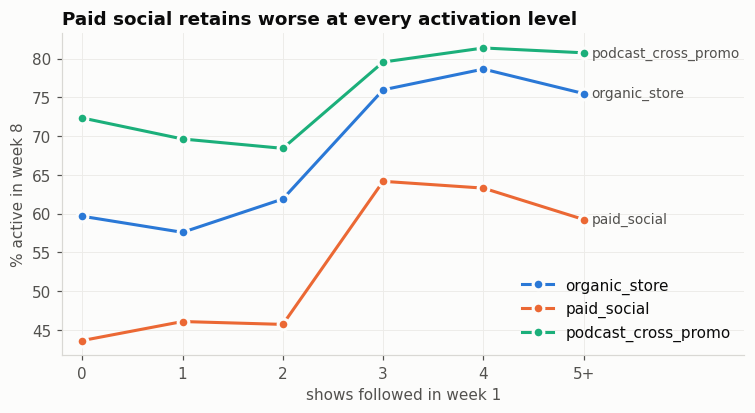

,raw W8,W8 standardised to the same shows mix,"gap vs organic (raw, pp)","gap vs organic (standardised, pp)"
acquisition_channel,,,,
organic_store,67.900,66.100,0.000,0.000
paid_social,49.900,52.000,-18.000,-14.100
podcast_cross_promo,74.500,73.700,6.600,7.600


In [24]:
like = STD[STD.max_age_obs >= 8].assign(w8=lambda d: active_at(d.user_id, 8), shows=lambda d: d.shows_followed_week1.clip(upper=5))
strat = like.pivot_table(index='shows', columns='acquisition_channel', values='w8', aggfunc='mean')
nstrat = like.pivot_table(index='shows', columns='acquisition_channel', values='w8', aggfunc='size')
print('Week-8 retention by channel WITHIN each "shows followed" level (%):')
display((strat * 100).round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
for ch in CHANNELS:
    ax.plot(strat.index, strat[ch] * 100, color=CH_COLORS[ch], marker='o', markersize=7, markeredgecolor=SURFACE, markeredgewidth=2, label=ch)
    end_label(ax, strat.index[-1], strat[ch].iloc[-1] * 100, ch)
ax.set_xticks(strat.index, ['0', '1', '2', '3', '4', '5+'])
ax.set_xlabel('shows followed in week 1'); ax.set_ylabel('% active in week 8'); ax.set_xlim(-0.2, 6.6)
ax.set_title('Paid social retains worse at every activation level')
ax.legend(loc='lower right')
save(fig, '04_like_with_like'); plt.show()

# direct standardisation: give every channel the same "shows followed" mix (the overall one)
mix = like.shows.value_counts(normalize=True).sort_index()
std_ret = (strat.mul(mix, axis=0)).sum()
raw_ret = like.groupby('acquisition_channel').w8.mean()
comp = pd.DataFrame({'raw W8': raw_ret, 'W8 standardised to the same shows mix': std_ret}) * 100
comp['gap vs organic (raw, pp)'] = comp['raw W8'] - comp.loc['organic_store', 'raw W8']
comp['gap vs organic (standardised, pp)'] = comp['W8 standardised to the same shows mix'] - comp.loc['organic_store', 'W8 standardised to the same shows mix']
display(comp.round(1))

In [25]:
# Linear probability model: active in week 8 ~ channel + activation + shows + platform + age  (OLS with dummies)
X = pd.get_dummies(like[['acquisition_channel', 'platform', 'age_bucket']], drop_first=True).astype(float)
X['activated'] = like.activated.astype(float)
X['shows_followed_week1'] = like.shows_followed_week1.astype(float)
X.insert(0, 'const', 1.0)
y = like.w8.astype(float).values
beta, *_ = np.linalg.lstsq(X.values, y, rcond=None)
resid = y - X.values @ beta
sigma2 = resid @ resid / (len(y) - X.shape[1])
se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.values.T @ X.values)))
ols = pd.DataFrame({'effect on P(active W8), pp': beta * 100, 'std err, pp': se * 100, 't': beta / se}, index=X.columns)
display(ols.round(2))

,"effect on P(active W8), pp","std err, pp",t
const,60.510,1.240,48.690
acquisition_channel_paid_social,-14.640,0.910,-16.150
acquisition_channel_podcast_cross_promo,6.860,1.020,6.750
platform_iOS,-0.270,0.730,-0.370
age_bucket_25-34,0.610,0.970,0.630
age_bucket_35-44,-0.960,1.130,-0.850
age_bucket_45+,-1.650,1.240,-1.330
age_bucket_unknown,-1.110,2.160,-0.510
activated,15.360,1.320,11.660
shows_followed_week1,0.210,0.420,0.500


**Conclusion of section 4.**

* The paid_social gap is **partly a mix effect** (paid users follow fewer shows), but **most of it survives** once we compare like with like: standardising the shows mix shrinks the week-8 gap with organic only from −18 pp to −14 pp, and the regression gives −14.6 pp (t = −16) at equal activation, platform and age. Paid social brings intrinsically less engaged users.
* Podcast cross-promo users are the best, +7 pp vs organic at equal activation.
* **The age difference does not survive**: 18-24 year-olds retain worse only because they follow fewer shows; at equal activation, age has no significant effect (|t| < 1.4). Platform has no effect at all.
* Activation (3+ shows) is the biggest lever we can act on: +15 pp of week-8 retention on top of the channel effect.

## 5. Unit economics: CAC, retention, LTV, payback

### 5.1 Revenue per active user

In [26]:
act_rows = wf[wf.push_variant != 'aggressive_push']
arpu_w = act_rows.groupby('acquisition_channel').agg(ads_per_active_week=('ad_impressions', 'mean'),
                                                     minutes_per_active_week=('minutes', 'mean'),
                                                     revenue_per_active_week=('revenue', 'mean'))
arpu_w.loc['all'] = [act_rows.ad_impressions.mean(), act_rows.minutes.mean(), act_rows.revenue.mean()]
arpu_w['revenue_per_active_month (x 4.33)'] = arpu_w.revenue_per_active_week * 52 / 12
display(arpu_w.round(3))
print(f'Ads per listening hour: {ADS_PER_HOUR:.2f} -> 1 listening hour = EUR {ADS_PER_HOUR * REV_PER_AD:.3f}')

,ads_per_active_week,minutes_per_active_week,revenue_per_active_week,revenue_per_active_month (x 4.33)
acquisition_channel,,,,
organic_store,11.474,81.177,0.103,0.447
paid_social,11.600,82.036,0.104,0.452
podcast_cross_promo,11.455,80.975,0.103,0.447
all,11.510,81.407,0.104,0.449


Ads per listening hour: 8.57 -> 1 listening hour = EUR 0.077


An active user is worth about **€0.10 per week (≈ €0.45 per month)**. Intensity per active week is almost identical across channels, so **differences in LTV come almost entirely from retention**.

### 5.2 CAC

In [27]:
signups_m = u.groupby(['signup_month', 'acquisition_channel']).size().unstack()
ue = spend.set_index('month')[['spend_eur', 'spend_imputed']].join(signups_m)
ue['total_signups'] = signups_m.sum(axis=1)
ue['CAC paid_social'] = ue.spend_eur / ue.paid_social
ue['blended CAC (all signups)'] = ue.spend_eur / ue.total_signups
display(ue.round(2))
CAC_PAID = ue['CAC paid_social'].median()
print(f'CAC paid_social: EUR {CAC_PAID:.2f} (min {ue["CAC paid_social"].min():.2f}, max {ue["CAC paid_social"].max():.2f}) | blended CAC: EUR {ue["blended CAC (all signups)"].median():.2f}')

,spend_eur,spend_imputed,organic_store,paid_social,podcast_cross_promo,total_signups,CAC paid_social,blended CAC (all signups)
month,,,,,,,,
2025-01-01,990.000,False,300,380,150,830,2.610,1.190
2025-02-01,"1,020.000",False,312,391,157,860,2.610,1.190
2025-03-01,"1,050.000",False,324,403,165,892,2.610,1.180
2025-04-01,"1,080.000",False,337,415,173,925,2.600,1.170
2025-05-01,"1,115.000",True,350,427,182,959,2.610,1.160
2025-06-01,"1,150.000",False,364,440,191,995,2.610,1.160
2025-07-01,"1,180.000",False,379,453,201,1033,2.600,1.140
2025-08-01,"1,220.000",False,394,467,211,1072,2.610,1.140
2025-09-01,"1,250.000",False,410,481,221,1112,2.600,1.120


CAC paid_social: EUR 2.61 (min 2.60, max 2.61) | blended CAC: EUR 1.12


CAC is **flat at €2.61** over 18 months although spend grew by +65 %: paid_social has **not yet reached its saturation point** (course: paid channel dynamics). Every extra euro still buys the same number of users. The question is whether those users are worth €2.61.

### 5.3 LTV, LTV:CAC and payback by channel

In [28]:
ext_ch = {ch: extend(vc_ch[ch]) for ch in CHANNELS}
rows = {}
for ch in CHANNELS:
    e = ext_ch[ch]; cum = e.v.cumsum()
    cac = CAC_PAID if ch == 'paid_social' else 0.0
    payback = int((cum >= cac).idxmax()) if (cum >= cac).any() and cac > 0 else None
    rows[ch] = {
        'observed weeks': int(e.observed.sum()),
        'revenue per user, first 12 weeks': cum[11],
        'LTV 52 weeks': cum[51], 'LTV 104 weeks': cum[103],
        'share of LTV104 extrapolated': e.v[~e.observed].iloc[:104 - e.observed.sum()].sum() / cum[103] if e.observed.sum() < 104 else 0,
        'CAC': cac,
        'LTV104 : CAC': cum[103] / cac if cac else np.nan,
        'payback (weeks)': payback if payback is not None else ('> 160' if cac else 'n/a (no spend)'),
    }
ltv = pd.DataFrame(rows).T
display(ltv)

,observed weeks,"revenue per user, first 12 weeks",LTV 52 weeks,LTV 104 weeks,share of LTV104 extrapolated,CAC,LTV104 : CAC,payback (weeks)
organic_store,75,0.990,2.549,3.650,0.148,0.000,NaN,n/a (no spend)
paid_social,76,0.840,1.604,2.035,0.108,2.605,0.781,> 160
podcast_cross_promo,73,1.039,2.927,4.264,0.159,0.000,NaN,n/a (no spend)


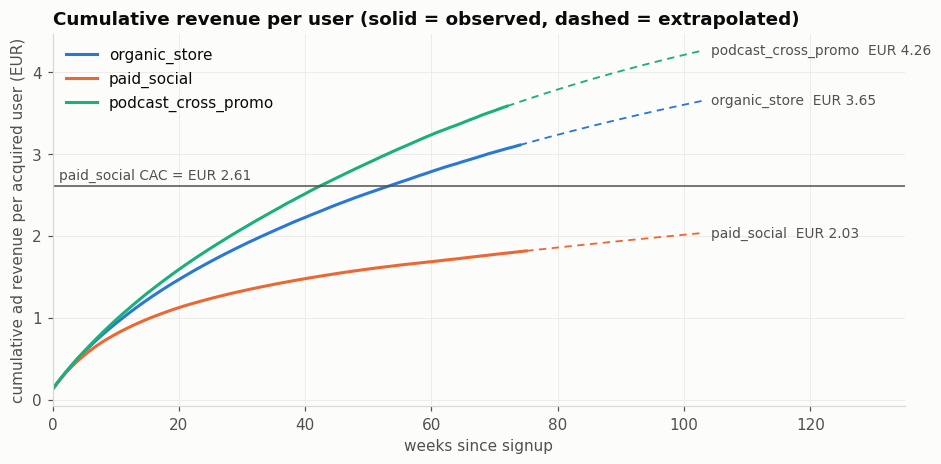

In [29]:
fig, ax = plt.subplots(figsize=(10, 4.4))
for ch in CHANNELS:
    e = ext_ch[ch]; cum = e.v.cumsum().iloc[:104]
    K = int(e.observed.iloc[:104].sum()) - 1
    ax.plot(cum.index[:K + 1], cum.iloc[:K + 1], color=CH_COLORS[ch], label=ch)
    ax.plot(cum.index[K:], cum.iloc[K:], color=CH_COLORS[ch], linewidth=1.2, linestyle=(0, (4, 3)))
    end_label(ax, 103, cum.iloc[-1], f'{ch}  EUR {cum.iloc[-1]:.2f}')
ax.axhline(CAC_PAID, color=INK2, linewidth=1)
ax.text(1, CAC_PAID + 0.08, f'paid_social CAC = EUR {CAC_PAID:.2f}', fontsize=9, color=INK2)
ax.set_xlim(0, 135); ax.set_xlabel('weeks since signup'); ax.set_ylabel('cumulative ad revenue per acquired user (EUR)')
ax.set_title('Cumulative revenue per user (solid = observed, dashed = extrapolated)')
ax.legend(loc='upper left')
save(fig, '05_ltv_curves'); plt.show()

**Paid social does not pay back.** A paid user generates about **€1.60 in 52 weeks and €2.04 in two years**, against a CAC of **€2.61**: **LTV:CAC ≈ 0.78 < 1**, so Echo *loses money on every paid user* even before any operating cost (the course threshold for a healthy business is LTV ≥ 3 × CAC). Organic (€3.65) and cross-promo (€4.26) users are worth about twice as much over two years and cost nothing in media. About 85-90 % of these LTVs are observed, not extrapolated.

*Caveats:* (1) LTV is gross ad revenue, a real gross margin (hosting, content rights, ad-tech fees) would make paid_social even worse; (2) we ignore any indirect value of paid users (word of mouth, ranking in the store) for which there is no data; (3) the tail after the observed horizon is extrapolated.

### 5.4 Unit economics by cohort (like with like: same 12-week horizon)

In [30]:
coh = STD[STD.max_age_obs >= 11].copy()
rev12 = wf[(wf.age_wk <= 11) & wf.user_id.isin(coh.user_id)].groupby('user_id').revenue.sum()
coh['rev12'] = coh.user_id.map(rev12).fillna(0)
coh['w12'] = active_at(coh.user_id, 11)
coh['quarter'] = coh.signup_date.dt.to_period('Q').astype(str)
cq = coh.pivot_table(index='quarter', columns='acquisition_channel', values='rev12', aggfunc='mean')
print('12-week revenue per acquired user (EUR), by signup quarter and channel:')
display(cq.round(3))
print('12-week payback ratio of paid_social (12-week revenue / CAC):')
display((cq.paid_social / CAC_PAID).round(2).to_frame('rev12 / CAC'))

12-week revenue per acquired user (EUR), by signup quarter and channel:


acquisition_channel,organic_store,paid_social,podcast_cross_promo
quarter,,,
2025Q1,1.012,0.854,1.051
2025Q2,0.973,0.833,1.023
2025Q3,0.988,0.834,1.036
2025Q4,1.005,0.828,1.051
2026Q1,0.975,0.860,1.038
2026Q2,1.000,0.837,1.039


12-week payback ratio of paid_social (12-week revenue / CAC):


,rev12 / CAC
quarter,
2025Q1,0.330
2025Q2,0.320
2025Q3,0.320
2025Q4,0.320
2026Q1,0.330
2026Q2,0.320


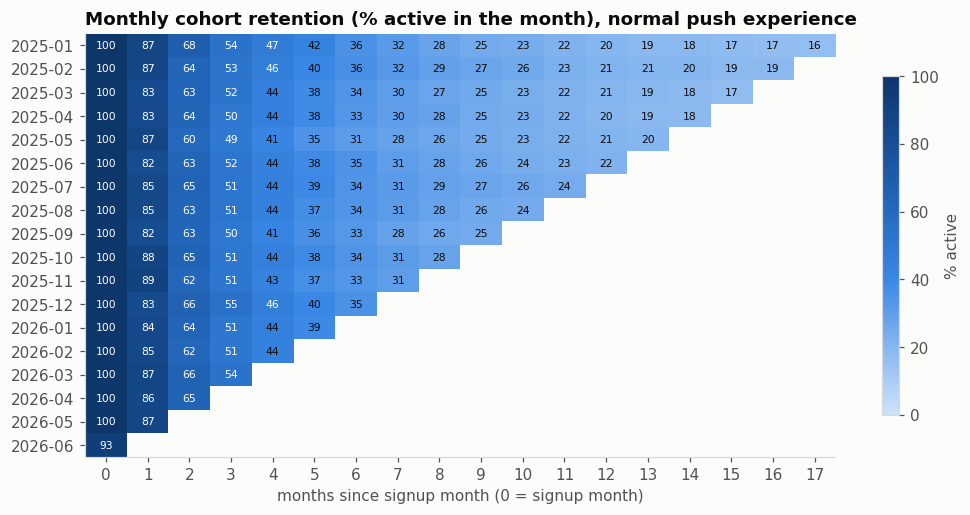

In [31]:
# classic cohort triangle (course slide "cohort analysis"): % of a monthly cohort active in calendar month m+k
um = wf[['user_id', 'week_start']].assign(month=lambda d: d.week_start.dt.to_period('M')).drop_duplicates(['user_id', 'month'])
um = um.merge(u[['user_id', 'signup_month']].assign(cm=lambda d: d.signup_month.dt.to_period('M')), on='user_id')
um['k'] = (um.month - um.cm).apply(lambda x: x.n)
um = um[um.k >= 0]   # the signup week can start in the previous calendar month: not a "month -1" of life
size = STD.groupby(STD.signup_month.dt.to_period('M')).size()
tri = um[um.user_id.isin(STD.user_id)].groupby(['cm', 'k']).user_id.nunique().unstack()
tri = tri.div(size, axis=0)
tri = tri.loc[:, 0:17]
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(tri.values * 100, cmap=SEQ, vmin=0, vmax=100, aspect='auto')
for i in range(tri.shape[0]):
    for j in range(tri.shape[1]):
        val = tri.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f'{val*100:.0f}', ha='center', va='center', fontsize=7, color='white' if val > 0.45 else INK)
ax.set_xticks(range(tri.shape[1]), tri.columns); ax.set_yticks(range(tri.shape[0]), [str(p) for p in tri.index])
ax.set_xlabel('months since signup month (0 = signup month)'); ax.set_title('Monthly cohort retention (% active in the month), normal push experience')
ax.grid(False); fig.colorbar(im, ax=ax, label='% active', shrink=0.8)
save(fig, '05_cohort_triangle'); plt.show()

Paid social recovers only **a third of its CAC in the first 12 weeks**, in every quarter. The cohort triangle is **remarkably stable**: every monthly cohort since January 2025 has the same shape (~85 % active in the month after signup, ~64 % in month 2, ~51 % in month 3, ~44 % in month 4, ~25 % after 9 months). There is no sign that the product got better or worse over 18 months for users with normal notifications, and paid_social cohort value does not degrade as spend grows. The latest cell of each row is slightly understated because June 2026 is only observed until the 28th.

## 6. What changed during these 18 months?

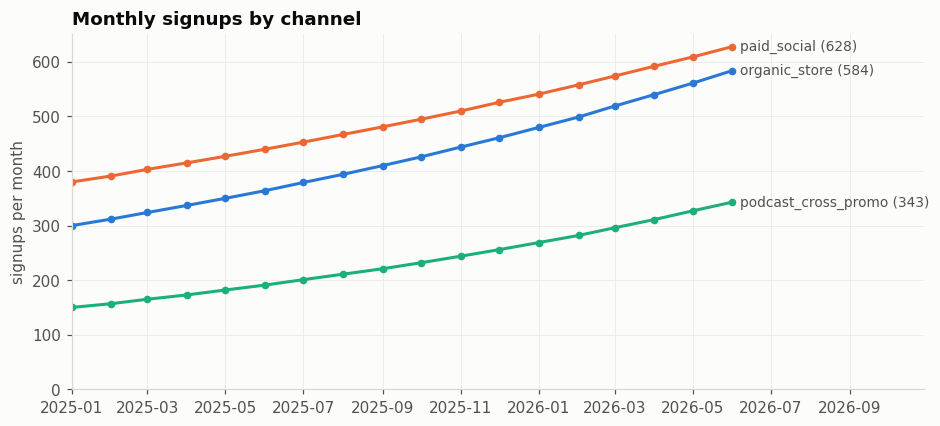

Compound monthly growth rate (log-linear fit): {'organic_store': '4.00%', 'paid_social': '3.00%', 'podcast_cross_promo': '5.00%', 'paid spend': '2.98%'}
Channel mix first vs last month: {'organic_store': 0.361, 'paid_social': 0.458, 'podcast_cross_promo': 0.181} -> {'organic_store': 0.376, 'paid_social': 0.404, 'podcast_cross_promo': 0.221}


In [32]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for ch in CHANNELS:
    ax.plot(signups_m.index, signups_m[ch], color=CH_COLORS[ch], marker='o', markersize=4)
    end_label(ax, signups_m.index[-1], signups_m[ch].iloc[-1], f'{ch} ({signups_m[ch].iloc[-1]:,})')
ax.set_xlim(signups_m.index[0], signups_m.index[-1] + pd.Timedelta(days=150))
ax.set_ylabel('signups per month'); ax.set_ylim(0)
ax.set_title('Monthly signups by channel')
save(fig, '06_signups_by_channel'); plt.show()

months_n = np.arange(len(signups_m))
growth = {ch: np.exp(np.polyfit(months_n, np.log(signups_m[ch]), 1)[0]) - 1 for ch in CHANNELS}
growth['paid spend'] = np.exp(np.polyfit(months_n, np.log(ue.spend_eur), 1)[0]) - 1
print('Compound monthly growth rate (log-linear fit):', {k: f'{v:.2%}' for k, v in growth.items()})
print('Channel mix first vs last month:', (signups_m.iloc[0] / signups_m.iloc[0].sum()).round(3).to_dict(), '->', (signups_m.iloc[-1] / signups_m.iloc[-1].sum()).round(3).to_dict())

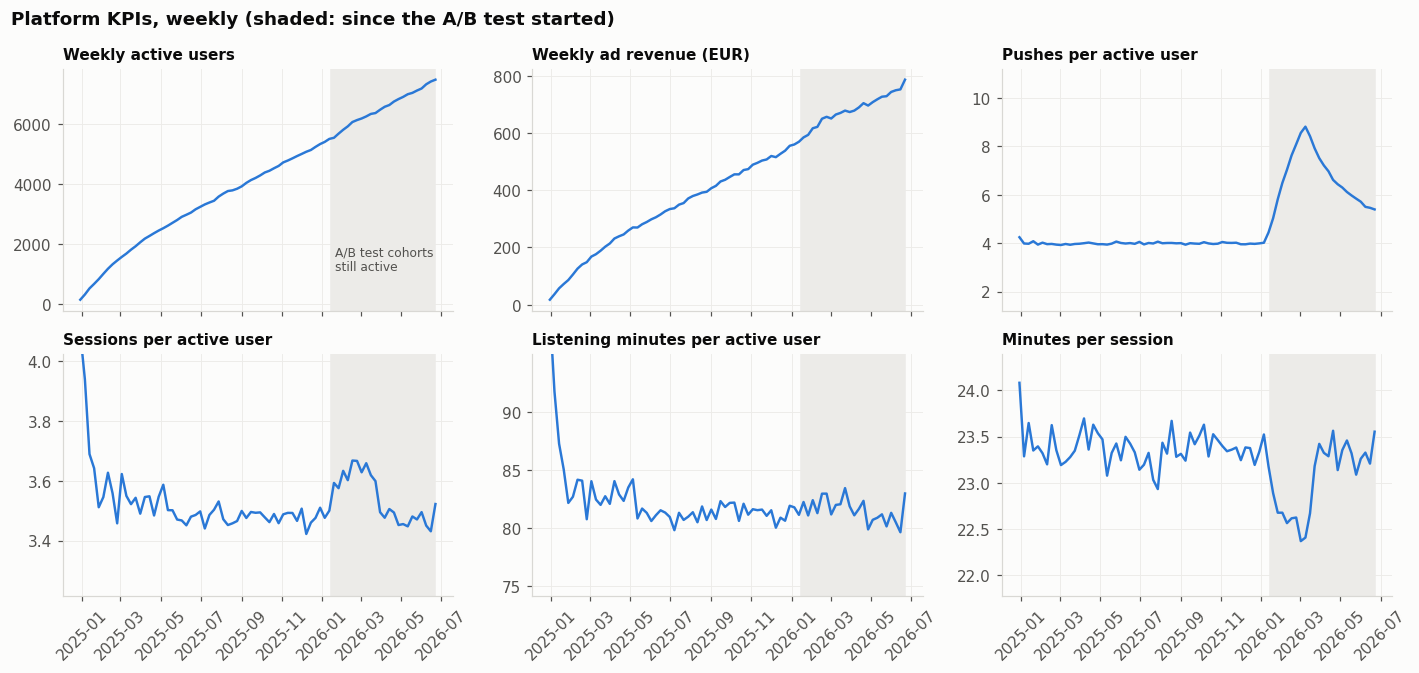

,WAU,sessions per WAU,minutes per WAU,pushes per WAU,minutes per session
week_start,,,,,
2025-12-01,4994,3.510,81.520,3.960,23.240
2025-12-08,5067,3.420,80.020,3.950,23.380
2025-12-15,5126,3.460,80.880,3.980,23.380
2025-12-22,5229,3.480,80.620,3.970,23.190
2025-12-29,5323,3.510,81.910,3.990,23.330
2026-01-05,5395,3.480,81.770,4.020,23.520
2026-01-12,5495,3.500,81.120,4.440,23.180
2026-01-19,5532,3.590,82.230,5.030,22.890
2026-01-26,5670,3.580,81.070,5.810,22.670


In [33]:
kpi = wf.groupby('week_start').agg(WAU=('user_id', 'nunique'), sessions=('sessions', 'sum'), minutes=('minutes', 'sum'),
                                   ads=('ad_impressions', 'sum'), push=('push_notifications_received', 'sum'), revenue=('revenue', 'sum'))
kpi['sessions per WAU'] = kpi.sessions / kpi.WAU
kpi['minutes per WAU'] = kpi.minutes / kpi.WAU
kpi['pushes per WAU'] = kpi.push / kpi.WAU
kpi['minutes per session'] = kpi.minutes / kpi.sessions
kpi['listening hours'] = kpi.minutes / 60

panels = [('WAU', 'Weekly active users'), ('revenue', 'Weekly ad revenue (EUR)'), ('pushes per WAU', 'Pushes per active user'),
          ('sessions per WAU', 'Sessions per active user'), ('minutes per WAU', 'Listening minutes per active user'), ('minutes per session', 'Minutes per session')]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2), sharex=True)
for ax, (col, title) in zip(axes.flat, panels):
    ax.axvspan(TEST_START, LAST_FULL_WEEK, color='#ecebe8', zorder=0)
    ax.plot(kpi.index, kpi[col], color=BLUE, linewidth=1.6)
    ax.set_title(title, fontsize=10)
    if col not in ('WAU', 'revenue'):
        lo, hi = kpi[col].quantile(.02), kpi[col].quantile(.98); pad = (hi - lo) * 0.6
        ax.set_ylim(lo - pad, hi + pad)
for ax in axes[1]:
    ax.tick_params(axis='x', rotation=45)
axes[0, 0].text(TEST_START + pd.Timedelta(days=5), kpi.WAU.max() * 0.15, 'A/B test cohorts\nstill active', fontsize=8, color=INK2)
fig.suptitle('Platform KPIs, weekly (shaded: since the A/B test started)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save(fig, '06_platform_kpis'); plt.show()
display(kpi.loc['2025-12-01':'2026-04-30', ['WAU', 'sessions per WAU', 'minutes per WAU', 'pushes per WAU', 'minutes per session']].round(2))

**What changed, and what did each change cause:**

| Change | Evidence | Effect |
|---|---|---|
| Steady growth of signups on all channels (organic +4 %/month, paid +3 %, cross-promo +5 %) | signups chart | WAU grew to ~7.5k; revenue grows with WAU, intensity per user is flat |
| Paid social budget +3 %/month (€990 → €1,630) | spend file | Paid signups grew in proportion; **CAC flat (no saturation)**, but each paid user still loses money |
| Mix shift away from paid social (46 % → 40 % of signups) towards cross-promo (18 % → 22 %) | channel mix | Slight improvement of the average retention of the user base |
| **A/B test, 15 Jan - 15 Mar 2026** (half of new users get ~32 pushes/week instead of 4, and keep getting them after the window) | pushes per active user jump from 4 to 8.8 and stay high | **Sessions per active user rise ~5 % at platform level, minutes per active user do not move and minutes per session fall**: more app opens, not more listening |
| Data incidents | none: no tracking gap, stable ads per hour (8.5) | – |

The 30 % "sessions" increase is visible at platform level as a bump in sessions per active user, with **no matching bump in listening or revenue**. Section 7 digs into this.

## 7. The A/B test: aggressive push vs control

**Design.** New users who signed up between 15 Jan and 15 Mar 2026 were randomly split: *control* (normal notifications) vs *aggressive_push* (≈5 notifications a day, "Don't miss out!" copy). The growth team's claim: *"sessions are up 30 %"*.

### 7.1 Is the experiment valid? (sample ratio mismatch and balance)

In [34]:
ut = u[u.push_variant.isin(['control', 'aggressive_push'])].copy()
H = int(ut.max_age_obs.min())          # every test user is observable for weeks 0..H
n_arm = ut.push_variant.value_counts()
srm_p = stats.chisquare(n_arm.values).pvalue
print(f'Arms: {n_arm.to_dict()} | SRM chi-square p = {srm_p:.2f} -> {"OK" if srm_p > 0.01 else "PROBLEM"}')
print(f'All test users are observable for weeks 0..{H} of their life (up to {int(ut.max_age_obs.max())} for the earliest).')
bal = []
for col in ['acquisition_channel', 'platform', 'age_bucket', 'activated']:
    ct = pd.crosstab(ut[col], ut.push_variant)
    bal.append({'covariate': col, 'chi2 p-value': stats.chi2_contingency(ct)[1]})
bal.append({'covariate': 'shows_followed_week1 (t-test)', 'chi2 p-value': stats.ttest_ind(*[g.shows_followed_week1 for _, g in ut.groupby('push_variant')]).pvalue})
display(pd.DataFrame(bal).round(3))
pushes = wf[wf.user_id.isin(ut.user_id)].groupby('push_variant').push_notifications_received.mean()
print('Pushes per active week:', pushes.round(1).to_dict())

Arms: {'control': 1366, 'aggressive_push': 1343} | SRM chi-square p = 0.66 -> OK
All test users are observable for weeks 0..15 of their life (up to 23 for the earliest).


,covariate,chi2 p-value
0,acquisition_channel,0.630
1,platform,0.627
2,age_bucket,0.263
3,activated,0.091
4,shows_followed_week1 (t-test),0.511


Pushes per active week: {'aggressive_push': 32.0, 'control': 4.0}


No sample-ratio mismatch and the arms are balanced on channel, platform, age and activation (all p > 0.05; the age split is the closest to the limit, but small). The treatment was really delivered: **~32 pushes per week vs 4**. One subtlety: `shows_followed_week1` is measured *during* week 1, so it could itself be affected by the treatment; it does not differ between arms.

### 7.2 Reproducing the "+30 % sessions" claim, and looking beyond it

In [35]:
def per_user(frame, users):
    g = frame.groupby('user_id').agg(active_weeks=('week_start', 'count'), sessions=('sessions', 'sum'), minutes=('minutes', 'sum'),
                                     ad_impressions=('ad_impressions', 'sum'), revenue=('revenue', 'sum'), pushes=('push_notifications_received', 'sum'))
    g = g.reindex(users.user_id).fillna(0)
    g['push_variant'] = users.set_index('user_id').push_variant
    return g

def lift_table(pu, metrics):
    rows = {}
    for m in metrics:
        c = pu.loc[pu.push_variant == 'control', m]; a = pu.loc[pu.push_variant == 'aggressive_push', m]
        rows[m] = {'control': c.mean(), 'aggressive_push': a.mean(), 'lift': a.mean() / c.mean() - 1,
                   'p-value (Welch)': stats.ttest_ind(a, c, equal_var=False).pvalue}
    t = pd.DataFrame(rows).T
    return t

T = wf[wf.user_id.isin(ut.user_id)]
claim = per_user(T[T.week_start <= pd.Timestamp('2026-03-09')], ut)       # calendar weeks of the test window
print('A) What the growth team saw: per user, during the test window (15 Jan - 15 Mar 2026)')
display(lift_table(claim, ['sessions', 'minutes', 'revenue']).style.format({'control': '{:.2f}', 'aggressive_push': '{:.2f}', 'lift': '{:+.1%}', 'p-value (Welch)': '{:.3g}'}))

full = per_user(T[T.age_wk <= H], ut)
full['minutes per session'] = full.minutes / full.sessions
print(f'B) The full picture: per acquired user over their first {H + 1} weeks of life (all users fully observed)')
display(lift_table(full, ['sessions', 'active_weeks', 'minutes', 'ad_impressions', 'revenue', 'pushes']).style.format({'control': '{:.2f}', 'aggressive_push': '{:.2f}', 'lift': '{:+.1%}', 'p-value (Welch)': '{:.3g}'}))
tot = T.groupby('push_variant')[['minutes', 'sessions', 'ad_impressions']].sum()
mps = tot.minutes / tot.sessions
aph = tot.ad_impressions / tot.minutes * 60
print('Minutes per session:', mps.round(1).to_dict(), '| ads per listening hour:', aph.round(2).to_dict())

A) What the growth team saw: per user, during the test window (15 Jan - 15 Mar 2026)


,control,aggressive_push,lift,p-value (Welch)
sessions,15.50,20.74,+33.8%,3.31e-44
minutes,364.39,372.17,+2.1%,0.348
revenue,0.46,0.54,+16.6%,7.53e-13


B) The full picture: per acquired user over their first 16 weeks of life (all users fully observed)


,control,aggressive_push,lift,p-value (Welch)
sessions,38.23,41.45,+8.4%,1.84e-05
active_weeks,10.87,9.82,-9.7%,3.34e-07
minutes,897.73,833.12,-7.2%,0.000266
ad_impressions,126.77,126.72,-0.0%,0.985
revenue,1.14,1.14,-0.0%,0.985
pushes,43.83,314.09,+616.6%,0


Minutes per session: {'aggressive_push': 20.4, 'control': 23.4} | ads per listening hour: {'aggressive_push': 9.07, 'control': 8.48}


The claim is **true but misleading**, and the short-term view is even more tempting than the team says:

* **During the test window** (what a dashboard showed in March), aggressive users had **+34 % sessions** and even **+17 % ad revenue**, with the same listening time (+2 %, not significant). Revenue rose without more listening because aggressive users got **9.1 ads per listening hour instead of 8.5**: each extra app open probably triggers an extra pre-roll ad.
* **Over the first 16 weeks of life** the picture flips: aggressive users are active **−10 % fewer weeks**, listen **−7 % less**, and generate **exactly the same revenue** (€1.14 vs €1.14, p = 0.99). The early gain has already been eaten by churn, and the gap keeps growing (next section).

Sessions are a **vanity metric** here: pushes inflate app opens (minutes per session fall from 23.4 to 20.4) without creating listening, which is the value users come for.

### 7.3 Retention: the hidden cost

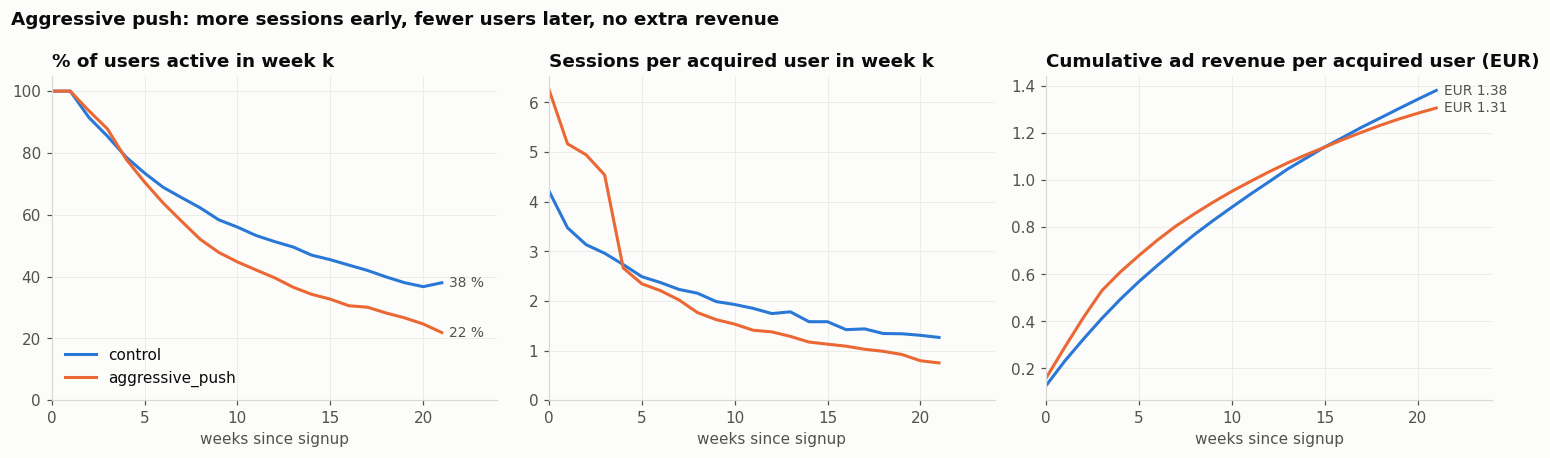

,control,aggressive_push,diff (pp),95% CI low,95% CI high,p-value
week 2,91.5%,93.7%,+2.2,+0.2,+4.1,0.032
week 4,78.7%,78.0%,-0.7,-3.8,+2.4,0.68
week 8,62.2%,52.0%,-10.2,-13.9,-6.5,8.7e-08
week 12,51.3%,39.6%,-11.7,-15.4,-8.0,9.6e-10
week 15,45.5%,32.7%,-12.8,-16.4,-9.1,9.7e-12


In [36]:
vc_ab = {arm: value_curves(ut[ut.push_variant == arm], min_n=300) for arm in ['control', 'aggressive_push']}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for arm, vc in vc_ab.items():
    axes[0].plot(vc.index, vc.S * 100, color=AB_COLORS[arm], label=arm)
    axes[1].plot(vc.index, vc.sess_per_user, color=AB_COLORS[arm], label=arm)
    axes[2].plot(vc.index, vc.v.cumsum(), color=AB_COLORS[arm], label=arm)
    end_label(axes[0], vc.index[-1], vc.S.iloc[-1] * 100, f'{vc.S.iloc[-1]*100:.0f} %')
    end_label(axes[2], vc.index[-1], vc.v.cumsum().iloc[-1], f'EUR {vc.v.cumsum().iloc[-1]:.2f}')
axes[0].set_title('% of users active in week k'); axes[0].set_ylim(0, 105)
axes[1].set_title('Sessions per acquired user in week k'); axes[1].set_ylim(0)
axes[2].set_title('Cumulative ad revenue per acquired user (EUR)')
for ax in axes:
    ax.set_xlabel('weeks since signup'); ax.set_xlim(0, max(vc.index.max() for vc in vc_ab.values()) + 3)
axes[0].legend(loc='lower left')
fig.suptitle('Aggressive push: more sessions early, fewer users later, no extra revenue', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(); save(fig, '07_ab_curves'); plt.show()

def ztest(k):
    obs = ut[ut.max_age_obs >= k]
    a = active_at(obs.user_id, k)
    c_, a_ = a[obs.push_variant.values == 'control'], a[obs.push_variant.values == 'aggressive_push']
    p1, p2, n1, n2 = c_.mean(), a_.mean(), len(c_), len(a_)
    p = (c_.sum() + a_.sum()) / (n1 + n2)
    z = (p2 - p1) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return {'control': p1, 'aggressive_push': p2, 'diff (pp)': (p2 - p1) * 100, '95% CI low': (p2 - p1 - 1.96 * se) * 100,
            '95% CI high': (p2 - p1 + 1.96 * se) * 100, 'p-value': 2 * stats.norm.sf(abs(z))}
ret_ab = pd.DataFrame({f'week {k}': ztest(k) for k in [2, 4, 8, 12, H]}).T
display(ret_ab.style.format({'control': '{:.1%}', 'aggressive_push': '{:.1%}', 'diff (pp)': '{:+.1f}', '95% CI low': '{:+.1f}', '95% CI high': '{:+.1f}', 'p-value': '{:.2g}'}))

The aggressive arm is slightly *more* active in week 2 (+2 pp, the pushes pull people back), equal in week 4, then **retention collapses**: −10 pp in week 8, −12 pp in week 12, **−13 pp in week 15** (45.5 % → 32.7 %, about **−28 % relative**, p < 10⁻¹¹), a gap that is still widening when the data ends. This is the dark-pattern signature from the course: short-term win on an engagement metric, long-term loss of trust and users.

### 7.4 Does it hurt every segment? (heterogeneity)

,segment,n,control W12,aggressive W12,diff (pp),ci
0,acquisition_channel = organic_store,1027,0.571,0.469,-10.228,6.085
1,acquisition_channel = paid_social,1115,0.406,0.257,-14.899,5.454
2,acquisition_channel = podcast_cross_promo,567,0.627,0.528,-9.946,8.104
3,platform = Android,1337,0.505,0.387,-11.794,5.295
4,platform = iOS,1372,0.521,0.405,-11.651,5.245
5,age_bucket = 18-24,763,0.486,0.354,-13.255,6.956
6,age_bucket = 25-34,927,0.492,0.412,-8.047,6.397
7,age_bucket = 35-44,521,0.554,0.452,-10.152,8.564
8,age_bucket = 45+,413,0.561,0.377,-18.386,9.497
9,age_bucket = unknown,85,0.512,0.341,-17.129,20.993


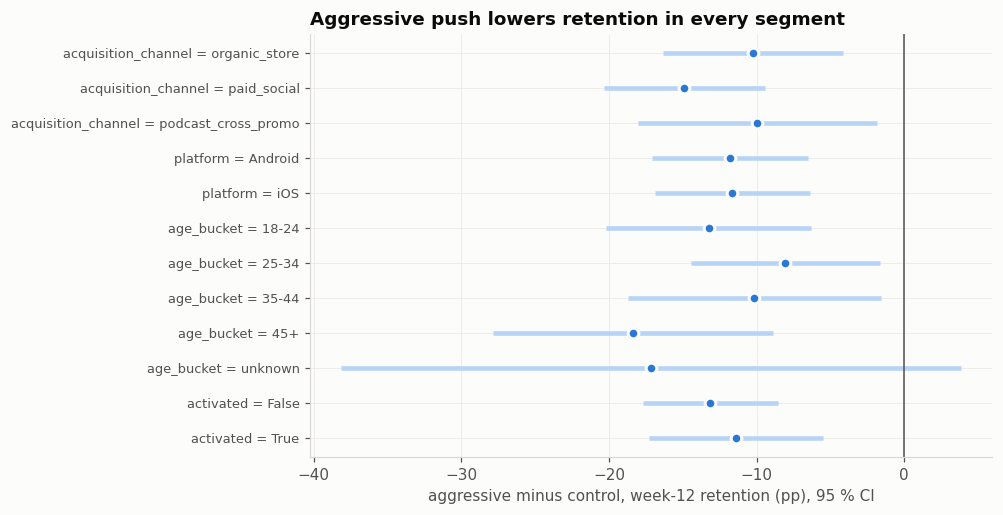

In [37]:
ut['w12'] = active_at(ut.user_id, 12)
het = []
for col in ['acquisition_channel', 'platform', 'age_bucket', 'activated']:
    for val, g in ut.groupby(col):
        c = g.loc[g.push_variant == 'control', 'w12']; a = g.loc[g.push_variant == 'aggressive_push', 'w12']
        d = a.mean() - c.mean(); se = np.sqrt(a.var() / len(a) + c.var() / len(c))
        het.append({'segment': f'{col} = {val}', 'n': len(g), 'control W12': c.mean(), 'aggressive W12': a.mean(),
                    'diff (pp)': d * 100, 'ci': 1.96 * se * 100})
het = pd.DataFrame(het)
display(het.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
yy = np.arange(len(het))[::-1]
ax.errorbar(het['diff (pp)'], yy, xerr=het.ci, fmt='o', color=BLUE, ecolor='#b7d3f6', elinewidth=3, markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
ax.axvline(0, color=INK2, linewidth=1)
ax.set_yticks(yy, het.segment, fontsize=8.5)
ax.set_xlabel('aggressive minus control, week-12 retention (pp), 95 % CI')
ax.set_title('Aggressive push lowers retention in every segment')
save(fig, '07_ab_heterogeneity'); plt.show()

The effect is negative in **every** segment. No sub-population (not even 18-24 year-olds or non-activated users) would justify a targeted rollout. Paid_social users, already the most fragile, are hit hardest.

### 7.5 What would a rollout cost? (LTV of an acquired user)

In [38]:
vc_std_all = value_curves(STD, min_n=200)
e_std = extend(vc_std_all)

def ab_ltv(vc, H, horizon=160):
    """Observed value for weeks 0..H, then: active share at H x standard decay shape x revenue per active week of the arm."""
    late = vc.loc[8:H]
    r_late = late.rev.sum() / late.active.sum()
    v = np.zeros(horizon); S = np.zeros(horizon)
    v[:H + 1] = vc.v.loc[:H].values; S[:H + 1] = vc.S.loc[:H].values
    rel = e_std.S.values[:horizon] / e_std.S.values[H]
    S[H + 1:] = vc.S.loc[H] * rel[H + 1:]
    v[H + 1:] = S[H + 1:] * r_late
    return pd.DataFrame({'S': S, 'v': v})

ab_ext = {arm: ab_ltv(vc, H) for arm, vc in vc_ab.items()}
res = pd.DataFrame({arm: {f'revenue weeks 0-{H} (observed)': e.v[:H + 1].sum(), 'LTV 52 weeks': e.v[:52].sum(),
                          'LTV 104 weeks': e.v[:104].sum(), 'active share week 26': e.S[26], 'active share week 52': e.S[52]}
                    for arm, e in ab_ext.items()})
res['aggressive vs control'] = res.aggressive_push / res.control - 1
display(res.style.format({'control': '{:.3f}', 'aggressive_push': '{:.3f}', 'aggressive vs control': '{:+.1%}'}))

# bootstrap CI of the observed revenue difference per user
rng = np.random.default_rng(42)
rc = full.loc[full.push_variant == 'control', 'revenue'].values; ra = full.loc[full.push_variant == 'aggressive_push', 'revenue'].values
boot = np.array([rng.choice(ra, len(ra)).mean() - rng.choice(rc, len(rc)).mean() for _ in range(5000)])
print(f'Observed revenue per user, weeks 0-{H}: diff = EUR {ra.mean() - rc.mean():+.3f}, 95 % bootstrap CI [{np.percentile(boot, 2.5):+.3f}; {np.percentile(boot, 97.5):+.3f}]')

new_per_year = u[u.signup_date >= '2025-07-01'].shape[0]
d_ltv = res.loc['LTV 104 weeks', 'aggressive_push'] - res.loc['LTV 104 weeks', 'control']
d_w26 = res.loc['active share week 26', 'aggressive_push'] - res.loc['active share week 26', 'control']
print(f'Per 10,000 new users: {d_w26 * 1e4:+,.0f} active users at week 26 and EUR {d_ltv * 1e4:+,.0f} of 2-year ad revenue')
print(f'At the last 12 months of signups ({new_per_year:,} users), new users alone: EUR {d_ltv * new_per_year:+,.0f} over 2 years')

,control,aggressive_push,aggressive vs control
revenue weeks 0-15 (observed),1.141,1.140,-0.0%
LTV 52 weeks,2.231,1.913,-14.2%
LTV 104 weeks,3.070,2.509,-18.3%
active share week 26,0.328,0.236,-28.1%
active share week 52,0.205,0.148,-28.1%


Observed revenue per user, weeks 0-15: diff = EUR -0.000, 95 % bootstrap CI [-0.044; +0.043]
Per 10,000 new users: -921 active users at week 26 and EUR -5,618 of 2-year ad revenue
At the last 12 months of signups (15,324 users), new users alone: EUR -8,609 over 2 years


**Answer to the board: do not roll out aggressive push notifications.**

1. The "+30 % sessions" is real but it is a **vanity metric**: sessions are app opens, user value is listening. Listening per user does not rise in the short term and falls by 7 % over 16 weeks.
2. The short-term revenue gain (+17 % during the window) comes from extra ads per app open and is **front-loaded**: after 16 weeks revenue per user is already equal in both arms.
3. Retention falls from week 8 onwards in **every segment** (−13 pp at week 15, p < 10⁻¹¹) and the gap is still widening: 28 % fewer users are still active at week 26.
4. Projected over two years, a user under aggressive push is worth **18 % less** (€2.51 vs €3.07): about **−€5,600 of revenue and −920 active users at week 26 per 10,000 new users**.
5. It is a **dark pattern** (fear-of-missing-out copy, 5 notifications a day). The course's quiz (slide 86-87) describes exactly this case: daily actives up, complaints up → *temporary gain, damages trust and long-term retention*. The data now proves it for Echo.
6. Rolling it out to *existing* users would add the same erosion to the current base: **−16 % revenue and −23 % WAU after 12 months** in the pessimistic scenario (section 9).

## 8. North Star Metric

In [39]:
nsm = STD[STD.max_age_obs >= 11][['user_id']].copy()
agg12 = wf[wf.user_id.isin(nsm.user_id) & (wf.age_wk <= 11)].groupby('user_id').agg(sessions=('sessions', 'sum'), minutes=('minutes', 'sum'), revenue=('revenue', 'sum'), active_weeks=('week_start', 'count'))
print('Correlation with ad revenue per user over 12 weeks (standard users):')
print(agg12.corr()['revenue'].drop('revenue').round(3).to_string())
row = wf[wf.push_variant != 'aggressive_push']
print('\nRow level (user-week) correlation with ad impressions: minutes', round(row.minutes.corr(row.ad_impressions), 3), '| sessions', round(row.sessions.corr(row.ad_impressions), 3))

Correlation with ad revenue per user over 12 weeks (standard users):
sessions       0.984
minutes        0.993
active_weeks   0.902

Row level (user-week) correlation with ad impressions: minutes 0.969 | sessions 0.914


| Candidate | Reflects user value? | Drives revenue? | Can be gamed? | Verdict |
|---|---|---|---|---|
| Sessions / DAU | weakly (an open is not a listen) | weakly | **yes**: the A/B test inflated it by 30 % while destroying value | vanity metric |
| WAU | partly | yes | yes (push reactivation) | good input metric |
| Ad impressions / revenue | no (it is the company's value, not the user's) | by definition | yes (more ads per hour) | business output |
| **Weekly listening hours** | **yes: listening is the core value** | **yes: ads are served at a constant 8.5 per hour** | hard: users must actually listen | **North Star** |

**North Star Metric: weekly listening hours** (total hours of podcasts listened per week across all users).

* It captures the core value: people listening to shows they chose.
* It drives revenue: in the normal regime ads are served at ~8.5 per listening hour (1 hour ≈ €0.077), and listening has the highest correlation with revenue (0.993 per user over 12 weeks).
* It is a retention-and-engagement metric, as the course recommends.
* It is hard to game. In normal times sessions also correlate with revenue (0.98), but the A/B test shows that sessions, and even short-term ad revenue, can be inflated by pushes without any extra listening. With listening hours as the primary metric, the aggressive test would have shown "flat" from day one, and "negative" by week 8.

**Metric tree (input metrics each team can own):**

```
Weekly listening hours
 = WAU  ×  listening hours per WAU
   │         └── shows followed, episode relevance, minutes per session   (content / product)
   └── WAU = new users × activation rate (>= 3 shows in week 1) × week-k retention
               │             │                                      └── relevant "new episode" pushes (CRM)
               │             └── onboarding (product)
               └── channel mix: cross-promo / organic / paid (marketing, judged on LTV:CAC)
```

Current NSM (average of the last 4 full weeks): 9,921 listening hours per week, = 7,340 WAU x 1.35 h per WAU


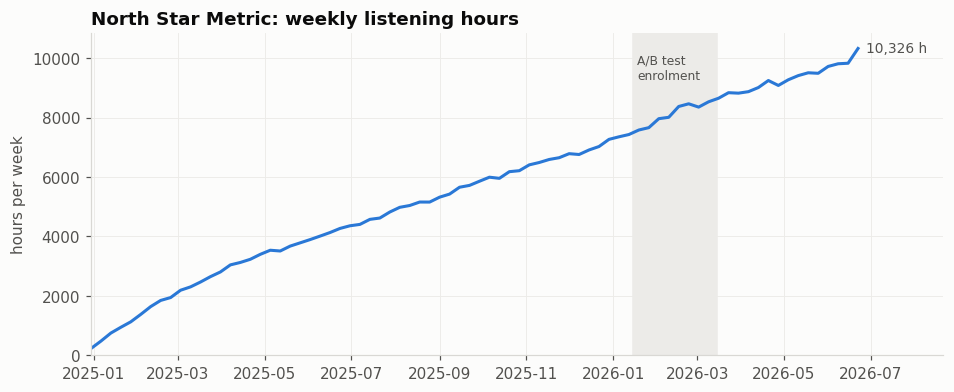

In [40]:
nsm_now = kpi['listening hours'].iloc[-4:].mean()
print(f'Current NSM (average of the last 4 full weeks): {nsm_now:,.0f} listening hours per week, '
      f'= {kpi.WAU.iloc[-4:].mean():,.0f} WAU x {kpi["minutes per WAU"].iloc[-4:].mean() / 60:.2f} h per WAU')
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(kpi.index, kpi['listening hours'], color=BLUE)
ax.axvspan(TEST_START, TEST_END, color='#ecebe8', zorder=0)
ax.text(TEST_START + pd.Timedelta(days=3), kpi['listening hours'].max() * 0.9, 'A/B test\nenrolment', fontsize=8, color=INK2)
end_label(ax, kpi.index[-1], kpi['listening hours'].iloc[-1], f'{kpi["listening hours"].iloc[-1]:,.0f} h')
ax.set_ylabel('hours per week'); ax.set_ylim(0); ax.set_xlim(kpi.index[0], kpi.index[-1] + pd.Timedelta(days=60))
ax.set_title('North Star Metric: weekly listening hours')
save(fig, '08_nsm'); plt.show()

## 9. Growth model: backtest and 3 scenarios

### 9.1 Model structure

The course model is $U_{t+1} = U_t\,(1 - churn) + NewUsers + Referrals$. A single churn rate does not fit Echo: churn is very high in the first weeks and low for tenured users (see the retention curves). We therefore use a **cohort model**, which is the same equation applied cohort by cohort:

$$WAU(t) = \sum_{g}\sum_{c \le t} N_{g,c}\; S_g(t-c) \qquad Revenue(t) = \sum_{g}\sum_{c \le t} N_{g,c}\; v_g(t-c)$$

* $g$ = segment = channel × activated (6 segments), $c$ = signup week, $N_{g,c}$ = new users.
* $S_g(k)$ = share of the segment active in week $k$ of life, $v_g(k)$ = ad revenue per acquired user in week $k$ (section 2.5 curves, extrapolated tail).
* **Inputs:** paid spend → paid users = spend / CAC; organic and cross-promo signups follow their log-linear trend; activation share by channel.
* **Parameters:** retention curves, revenue per active week, CAC, activation rate. **Outputs:** WAU, weekly revenue, listening hours (= revenue / €0.009 / 8.5 ads per hour).

In [41]:
GROUPS = [(ch, act) for ch in CHANNELS for act in (False, True)]

def build_curves(users_df, last_week, horizon=170):
    curves = {}
    for ch, act in GROUPS:
        g = users_df[(users_df.acquisition_channel == ch) & (users_df.activated == act) & (users_df.push_variant != 'aggressive_push')]
        curves[(ch, act)] = extend(value_curves(g, wf, last_week, min_n=100), horizon)
    return curves

def existing_cohorts(users_df):
    c = users_df.groupby(['signup_week', 'acquisition_channel', 'activated']).size().rename('n').reset_index()
    return c.rename(columns={'acquisition_channel': 'channel'}).assign(kind='existing')

def fit_trends(users_df, spend_df, fit_until):
    m = users_df[users_df.signup_month <= fit_until].groupby(['signup_month', 'acquisition_channel']).size().unstack()
    t = np.arange(len(m))
    sp = spend_df[spend_df.month <= fit_until].set_index('month').spend_eur
    return {'m0': m.index[0],
            'trends': {ch: np.polyfit(t, np.log(m[ch]), 1) for ch in ['organic_store', 'podcast_cross_promo']},
            'spend_trend': np.polyfit(t, np.log(sp.values), 1),
            'cac': (sp / m.paid_social).median(),
            'act': users_df[(users_df.signup_month <= fit_until) & (users_df.push_variant != 'aggressive_push')].groupby('acquisition_channel').activated.mean()}

def forecast_new(tr, start_day, end_day, spend_mult=1.0, act_uplift=0.0):
    days = pd.date_range(start_day, end_day, freq='D')
    month = days.to_period('M').to_timestamp()
    t = ((month.year - tr['m0'].year) * 12 + month.month - tr['m0'].month).values
    dim = days.days_in_month.values
    daily = {ch: np.exp(a + b * t) / dim for ch, (b, a) in tr['trends'].items()}
    b, a = tr['spend_trend']
    spend_daily = np.exp(a + b * t) * spend_mult / dim
    daily['paid_social'] = spend_daily / tr['cac']
    df = pd.DataFrame(daily, index=days)
    wk = df.groupby(days - pd.to_timedelta(days.dayofweek, unit='D'))[CHANNELS].sum()
    rows = []
    for sw, r in wk.iterrows():
        for ch in CHANNELS:
            p = min(tr['act'][ch] + act_uplift, 1.0)
            rows += [(sw, ch, True, r[ch] * p, 'new'), (sw, ch, False, r[ch] * (1 - p), 'new')]
    return pd.DataFrame(rows, columns=['signup_week', 'channel', 'activated', 'n', 'kind']), spend_daily.sum()

def simulate(weeks, cohorts, curves, new_ratio=None, rev_ratio=1.0, rollout=None, phi=1.0, phi_weeks=0, calib=1.0):
    weeks = pd.DatetimeIndex(weeks)
    W = np.zeros(len(weeks)); R = np.zeros(len(weeks))
    for row in cohorts.itertuples(index=False):
        c = curves[(row.channel, row.activated)]
        age = ((weeks - row.signup_week).days // 7).values
        m = (age >= 0) & (age < len(c))
        S = c.S.values[age[m]] * row.n; V = c.v.values[age[m]] * row.n
        if row.kind == 'new' and new_ratio is not None:
            f = new_ratio[np.minimum(age[m], len(new_ratio) - 1)]
            S, V = S * f, V * f * rev_ratio
        if row.kind == 'existing':
            S, V = S * calib, V * calib
            if rollout is not None:
                since = ((weeks[m] - rollout).days // 7).values + 1
                f = phi ** np.clip(since, 0, phi_weeks)
                S, V = S * f, V * f * np.where(since > 0, rev_ratio, 1.0)
        W[m] += S; R[m] += V
    return pd.DataFrame({'WAU': W, 'revenue': R}, index=weeks)

### 9.2 Backtest: calibrate on 2025, predict January - June 2026

Everything (retention curves, revenue per user, signup trends, spend trend, CAC, activation rates) is estimated **only with data available on 28 December 2025**, then the model predicts the next 26 weeks. We compare with what actually happened.

* **Backtest A (full model):** new signups are also forecast.
* **Backtest B:** actual signups are used, to isolate the error of the retention/revenue part.

,A: forecast signups,B: actual signups
MAPE WAU,+0.86%,+2.07%
MAPE revenue,+1.32%,+1.73%
"bias WAU, last week",+0.82%,+2.78%
bias 26-week revenue,-0.41%,+0.86%


Signups 29 Dec 2025 - 28 Jun 2026: forecast 8,308 vs actual 8,637 (-3.8%)


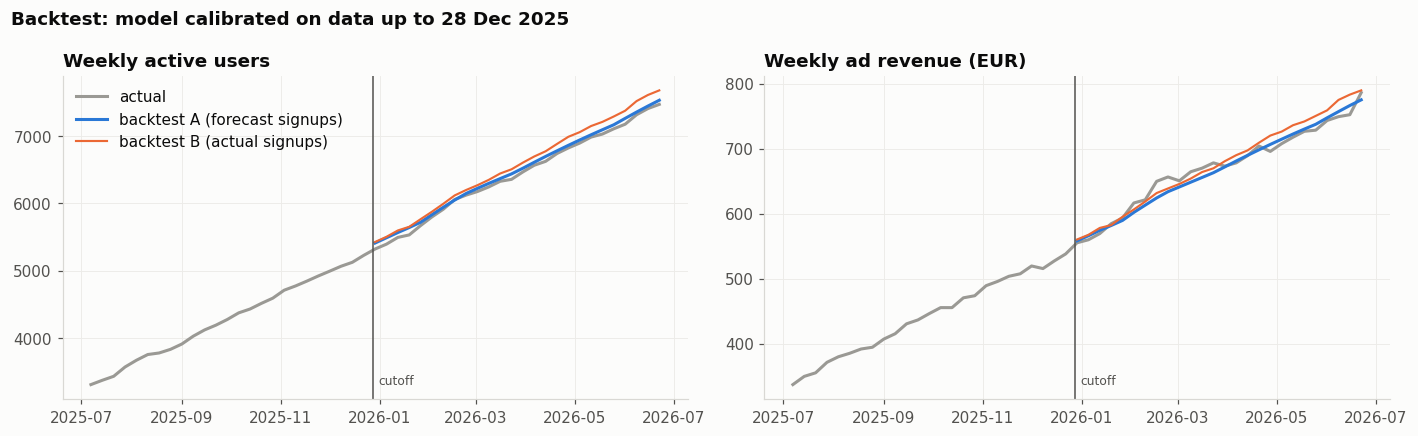

In [42]:
CUT_WEEK = pd.Timestamp('2025-12-22')          # last full week known at the cutoff
CUT_DAY = pd.Timestamp('2025-12-28')
u_train = u[u.signup_date <= CUT_DAY]
curves_bt = build_curves(u_train, CUT_WEEK)
tr_bt = fit_trends(u_train, spend, pd.Timestamp('2025-12-01'))
bt_weeks = pd.date_range('2025-12-29', LAST_FULL_WEEK, freq='W-MON')

new_bt, _ = forecast_new(tr_bt, '2025-12-29', LAST_FULL_WEEK + pd.Timedelta(days=6))
pred_A = simulate(bt_weeks, pd.concat([existing_cohorts(u_train), new_bt]), curves_bt)
actual_new = existing_cohorts(u[u.signup_date > CUT_DAY]).assign(kind='new')
pred_B = simulate(bt_weeks, pd.concat([existing_cohorts(u_train), actual_new]), curves_bt)
act = kpi.loc[bt_weeks, ['WAU', 'revenue']]

def mape(p, a): return (np.abs(p - a) / a).mean()
bt = pd.DataFrame({
    'A: forecast signups': {'MAPE WAU': mape(pred_A.WAU, act.WAU), 'MAPE revenue': mape(pred_A.revenue, act.revenue),
                            'bias WAU, last week': pred_A.WAU.iloc[-1] / act.WAU.iloc[-1] - 1, 'bias 26-week revenue': pred_A.revenue.sum() / act.revenue.sum() - 1},
    'B: actual signups': {'MAPE WAU': mape(pred_B.WAU, act.WAU), 'MAPE revenue': mape(pred_B.revenue, act.revenue),
                          'bias WAU, last week': pred_B.WAU.iloc[-1] / act.WAU.iloc[-1] - 1, 'bias 26-week revenue': pred_B.revenue.sum() / act.revenue.sum() - 1},
})
display(bt.style.format('{:+.2%}'))
sig_fore = new_bt.n.sum(); sig_act = actual_new.n.sum()
print(f'Signups 29 Dec 2025 - 28 Jun 2026: forecast {sig_fore:,.0f} vs actual {sig_act:,.0f} ({sig_fore / sig_act - 1:+.1%})')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
hist = kpi.loc['2025-07-01':]
for ax, col, title in [(axes[0], 'WAU', 'Weekly active users'), (axes[1], 'revenue', 'Weekly ad revenue (EUR)')]:
    ax.plot(hist.index, hist[col], color=GRAY, label='actual')
    ax.plot(pred_A.index, pred_A[col], color=BLUE, label='backtest A (forecast signups)')
    ax.plot(pred_B.index, pred_B[col], color=ORANGE, label='backtest B (actual signups)', linewidth=1.4)
    ax.axvline(CUT_DAY, color=INK2, linewidth=1); ax.text(CUT_DAY + pd.Timedelta(days=3), hist[col].min(), 'cutoff', fontsize=8, color=INK2)
    ax.set_title(title)
axes[0].legend(loc='upper left')
fig.suptitle('Backtest: model calibrated on data up to 28 Dec 2025', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(); save(fig, '09_backtest'); plt.show()

The model reproduces the first half of 2026 with **~1-2 % mean error** on WAU and revenue. Backtest B is the more informative one: with the true signups, the model **over-predicts WAU more and more after the test starts (+2.8 % by June)**. Half of the users who joined between 15 Jan and 15 Mar received aggressive push and churned faster, which a model calibrated on 2025 could not know. **The backtest error is the footprint of the A/B test.** Backtest A looks better only because two errors cancel out (signups under-forecast by 3.8 %, churn of the test cohort under-estimated).

### 9.3 Three scenarios for July 2026 → June 2027

The board's decision is the scenario variable. All scenarios start from the actual user base on 30 June 2026 (existing cohorts calibrated so that the model matches the actual WAU of the last full week).

| Scenario | Push policy | Activation | Paid spend | Assumptions from the data |
|---|---|---|---|---|
| **Pessimistic: aggressive push for everyone** | aggressive, all users | as today | trend (+3 %/month) | new users follow the aggressive/control retention ratio measured in the test (frozen after week 15) and its revenue per active week; existing users get the extra weekly loss measured in weeks 8-15 of the test, for 26 weeks |
| **Base: status quo** | normal | as today | trend | 2025-26 curves and trends continue |
| **Optimistic: guided onboarding** | normal | **+10 pp** of new users follow ≥ 3 shows | trend | moved users behave like activated users of their channel |

In [43]:
curves = build_curves(u, LAST_FULL_WEEK)
tr = fit_trends(u, spend, pd.Timestamp('2026-06-01'))
F_START, F_END = pd.Timestamp('2026-06-29'), pd.Timestamp('2027-06-21')
f_weeks = pd.date_range(F_START, F_END, freq='W-MON')
exist = existing_cohorts(u)

# calibration on the last full observed week
nowcast = simulate([LAST_FULL_WEEK], exist, curves)
CALIB = kpi.WAU.loc[LAST_FULL_WEEK] / nowcast.WAU.iloc[0]
print(f'Calibration factor for existing cohorts: {CALIB:.3f} (actual WAU {kpi.WAU.loc[LAST_FULL_WEEK]:,} vs model {nowcast.WAU.iloc[0]:,.0f})')

# parameters of the aggressive scenario, measured in the A/B test
Sc, Sa = vc_ab['control'].S.loc[:H], vc_ab['aggressive_push'].S.loc[:H]
ratio = (Sa / Sc).rolling(3, center=True, min_periods=1).mean().values
NEW_RATIO = np.concatenate([ratio, np.repeat(ratio[-1], 200)])
lc, la = vc_ab['control'].loc[2:H], vc_ab['aggressive_push'].loc[2:H]
REV_RATIO = (la.rev.sum() / la.active.sum()) / (lc.rev.sum() / lc.active.sum())
PHI = ((Sa.loc[H] / Sa.loc[8]) / (Sc.loc[H] / Sc.loc[8])) ** (1 / (H - 8))
APH_RATIO = aph['aggressive_push'] / aph['control']
print(f'Aggressive push: retention ratio at week {H} = {ratio[-1]:.2f}, revenue per active week ratio = {REV_RATIO:.3f}, '
      f'extra weekly retention factor on existing users = {PHI:.4f} (= {1 - PHI:.1%} extra loss per week)')

def run(name, act_uplift=0.0, spend_mult=1.0, aggressive=False, phi_weeks=26):
    new, spend_total = forecast_new(tr, '2026-07-01', F_END + pd.Timedelta(days=6), spend_mult, act_uplift)
    kw = dict(new_ratio=NEW_RATIO, rev_ratio=REV_RATIO, rollout=F_START, phi=PHI, phi_weeks=phi_weeks) if aggressive else {}
    sim = simulate(f_weeks, pd.concat([exist, new]), curves, calib=CALIB, **kw)
    aph = ADS_PER_HOUR * (APH_RATIO if aggressive else 1.0)    # aggressive push serves more ads per listening hour
    sim['listening hours'] = sim.revenue / REV_PER_AD / aph
    return name, sim, spend_total

scen = dict((n, (s, sp)) for n, s, sp in [
    run('Pessimistic: aggressive push for everyone', aggressive=True),
    run('Base: status quo'),
    run('Optimistic: guided onboarding (+10 pp activation)', act_uplift=0.10),
])
SC_COLORS = dict(zip(scen, [ORANGE, BLUE, AQUA]))

summ = pd.DataFrame({n: {'WAU end of June 2027': s.WAU.iloc[-1], 'average weekly listening hours (NSM)': s['listening hours'].mean(),
                         '12-month ad revenue (EUR)': s.revenue.sum(), '12-month paid spend (EUR)': sp,
                         'revenue - paid spend (EUR)': s.revenue.sum() - sp} for n, (s, sp) in scen.items()}).T
summ['revenue vs base'] = summ['12-month ad revenue (EUR)'] / summ.loc['Base: status quo', '12-month ad revenue (EUR)'] - 1
display(summ.style.format({c: '{:,.0f}' for c in summ.columns if c != 'revenue vs base'} | {'revenue vs base': '{:+.1%}'}))

Calibration factor for existing cohorts: 0.968 (actual WAU 7,468 vs model 7,715)
Aggressive push: retention ratio at week 15 = 0.72, revenue per active week ratio = 1.060, extra weekly retention factor on existing users = 0.9786 (= 2.1% extra loss per week)


,WAU end of June 2027,average weekly listening hours (NSM),12-month ad revenue (EUR),12-month paid spend (EUR),revenue - paid spend (EUR),revenue vs base
Pessimistic: aggressive push for everyone,"10,587","10,995","47,178","23,604","23,575",-16.0%
Base: status quo,"13,781","14,004","56,178","23,604","32,574",+0.0%
Optimistic: guided onboarding (+10 pp activation),"14,200","14,239","57,118","23,604","33,514",+1.7%


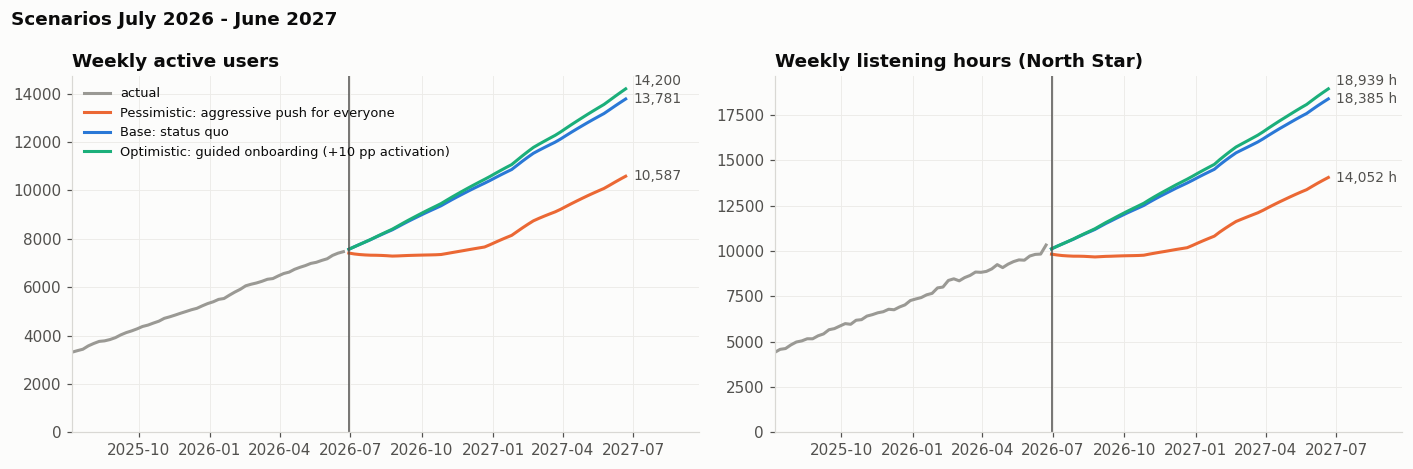

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
hist = kpi.loc['2025-07-01':]
axes[0].plot(hist.index, hist.WAU, color=GRAY, label='actual')
axes[1].plot(hist.index, hist['listening hours'], color=GRAY, label='actual')
for n, (s, _) in scen.items():
    axes[0].plot(s.index, s.WAU, color=SC_COLORS[n], label=n)
    axes[1].plot(s.index, s['listening hours'], color=SC_COLORS[n], label=n)
axes[0].set_title('Weekly active users'); axes[1].set_title('Weekly listening hours (North Star)')
for ax in axes:
    ax.axvline(F_START, color=INK2, linewidth=1); ax.set_xlim(hist.index[0], F_END + pd.Timedelta(days=95)); ax.set_ylim(0)
lx = F_END + pd.Timedelta(days=10)
end_labels(axes[0], lx, [(s.WAU.iloc[-1], f'{s.WAU.iloc[-1]:,.0f}') for s, _ in scen.values()])
end_labels(axes[1], lx, [(s['listening hours'].iloc[-1], f'{s["listening hours"].iloc[-1]:,.0f} h') for s, _ in scen.values()])
axes[0].legend(loc='upper left', fontsize=8.5)
fig.suptitle('Scenarios July 2026 - June 2027', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(); save(fig, '09_scenarios'); plt.show()

### 9.4 What-if experiments: one parameter at a time (course slide 98)

Sensitivity of the 12-month outcome to each lever, plus the key uncertainty of the pessimistic scenario (how long existing users keep eroding under aggressive push).

In [45]:
whatif = [
    ('Base', {}),
    ('Aggressive push, new users only', dict(aggressive=True, phi_weeks=0)),
    ('Aggressive push, existing users erode 26 weeks', dict(aggressive=True, phi_weeks=26)),
    ('Aggressive push, existing users erode 52 weeks', dict(aggressive=True, phi_weeks=52)),
    ('Activation +5 pp', dict(act_uplift=0.05)),
    ('Activation +10 pp', dict(act_uplift=0.10)),
    ('Paid social spend x 1.5', dict(spend_mult=1.5)),
    ('Paid social stopped', dict(spend_mult=0.0)),
]
wi = {}
for name, kw in whatif:
    _, s, sp = run(name, **kw)
    wi[name] = {'WAU June 2027': s.WAU.iloc[-1], '12-month revenue': s.revenue.sum(), '12-month paid spend': sp,
                'revenue - spend': s.revenue.sum() - sp}
wi = pd.DataFrame(wi).T
wi['delta (revenue - spend) vs base'] = wi['revenue - spend'] - wi.loc['Base', 'revenue - spend']
display(wi.style.format('{:,.0f}'))

,WAU June 2027,12-month revenue,12-month paid spend,revenue - spend,delta (revenue - spend) vs base
Base,"13,781","56,178","23,604","32,574",0
"Aggressive push, new users only","11,905","54,824","23,604","31,220","-1,354"
"Aggressive push, existing users erode 26 weeks","10,587","47,178","23,604","23,575","-9,000"
"Aggressive push, existing users erode 52 weeks","9,836","45,860","23,604","22,256","-10,318"
Activation +5 pp,"13,990","56,648","23,604","33,044",470
Activation +10 pp,"14,200","57,118","23,604","33,514",940
Paid social spend x 1.5,"15,224","61,127","35,406","25,722","-6,853"
Paid social stopped,"10,894","46,280",0,"46,280","13,705"


In [46]:
# value of activation: 2-year LTV per acquired user by channel and activation (model curves)
ltv_seg = pd.DataFrame({ch: {'not activated': curves[(ch, False)].v[:104].sum(), 'activated (>= 3 shows)': curves[(ch, True)].v[:104].sum()} for ch in CHANNELS}).T
ltv_seg['value of activating one user'] = ltv_seg['activated (>= 3 shows)'] - ltv_seg['not activated']
ltv_seg['activated LTV / paid CAC'] = ltv_seg['activated (>= 3 shows)'] / CAC_PAID
display(ltv_seg.round(2))

,not activated,activated (>= 3 shows),value of activating one user,activated LTV / paid CAC
organic_store,2.750,4.600,1.860,1.770
paid_social,1.590,3.330,1.750,1.280
podcast_cross_promo,3.310,5.420,2.110,2.080


Reading the scenarios and the what-if table:

* **Aggressive push is the worst option in every variant.** Even if only new users are affected, it costs WAU (−14 % in June 2027) and revenue. If existing users also erode, 12-month revenue falls by 16-18 % and WAU by 23-29 %.
* **Activation helps, but slowly.** +10 pp of new users following 3 shows adds only +1.7 % of revenue in the first 12 months, because 12-month revenue is dominated by the users Echo already has. It compounds: each extra activated user is worth €1.75-2.11 more over 2 years (table above), at no media cost.
* **Paid social destroys value at the margin.** +50 % budget adds €4.9k of revenue for €11.8k of spend. Stopping it would cut WAU by 21 % but improve "revenue − spend" by €13.7k over 12 months, because a paid user returns only ~60 % of its CAC in its first year and ~78 % in two years. Paid social is still the volume engine, so the recommendation is to **fix it before cutting it**. The table above shows why it can be fixed: an *activated* paid user is worth €3.33 over 2 years and pays back its €2.61 CAC, a non-activated one (75 % of paid signups) is worth €1.59 and never does. Target audiences likely to follow shows, onboard them to 3 shows, and cap CAC at the 2-year LTV (~€2.0 today, lower once costs are included).

## 10. A/B test plan: the next experiment

The data points to **activation** as the biggest lever, so the next test should not be about *more* notifications but about *better onboarding*.

In [47]:
def n_per_arm(p1, mde, alpha=0.05, power=0.8):
    p2 = p1 + mde; pbar = (p1 + p2) / 2
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return int(np.ceil((za * np.sqrt(2 * pbar * (1 - pbar)) + zb * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2 / mde ** 2))

base_w8 = active_at(STD[STD.max_age_obs >= 8].user_id, 8).mean()
base_act = STD.activated.mean()
weekly_signups = u[u.signup_date >= '2026-04-01'].shape[0] / ((EXTRACTION - pd.Timestamp('2026-04-01')).days / 7)
plan = []
for metric, p, mde in [('week-8 retention (primary)', base_w8, 0.03), ('week-8 retention (primary)', base_w8, 0.04),
                       ('activation >= 3 shows (secondary)', base_act, 0.05)]:
    n = n_per_arm(p, mde)
    plan.append({'metric': metric, 'baseline': p, 'MDE (pp)': mde * 100, 'users per arm': n,
                 'enrolment weeks (50/50 of all signups)': 2 * n / weekly_signups})
display(pd.DataFrame(plan).round(2))
print(f'Current signups per week: {weekly_signups:,.0f}')

,metric,baseline,MDE (pp),users per arm,enrolment weeks (50/50 of all signups)
0,week-8 retention (primary),0.610,3.000,4069,23.280
1,week-8 retention (primary),0.610,4.000,2276,13.020
2,activation >= 3 shows (secondary),0.380,5.000,1510,8.640


Current signups per week: 350


**Test: "Pick 3 shows" guided onboarding**

| Item | Plan |
|---|---|
| Hypothesis | If new users are guided to follow at least 3 shows during onboarding (personalised picks by age and channel, "follow 3 to continue" step that can be skipped), more users reach the aha moment, so week-8 retention and listening hours rise. |
| Unit and assignment | New user at signup, 50/50 random, **stratified by acquisition channel and platform**. Existing users are excluded. |
| Variants | Control: current onboarding. Treatment: guided "pick 3 shows" step. **Notifications identical in both arms** (normal policy) so that the effect is not confounded. |
| Primary metric | Week-8 retention (active in week 8 of life). |
| Secondary metrics | Share following ≥ 3 shows in week 1, listening hours per acquired user over 8 weeks (NSM per user), revenue per user. |
| Guardrails | Signup-to-first-listen completion (the extra step must not create drop-off), week-1 retention, ads per listening hour, push opt-out rate, app-store rating. |
| Size and duration | Baseline week-8 retention 61 %. ~4,100 users per arm for a 3 pp MDE (α = 5 %, power 80 %), i.e. ~23 weeks of enrolment at the current 350 signups per week; ~2,300 per arm for a 4 pp MDE (~13 weeks). The secondary metric (activation, baseline 38 %) needs only ~1,500 per arm for +5 pp, so a first read on the mechanism comes after ~9 weeks. Each user is followed for 8 weeks after signup. |
| Decision rule (pre-registered) | Ship if week-8 retention improves with p < 0.05 and no guardrail degrades by more than 1 pp. No peeking before the planned sample size; SRM check (χ²) every week. |
| Analysis | Two-proportion z-test on the primary metric, segment cuts by channel (paid_social expected to gain most), cohort curves up to week 8. |

**What the aggressive push test should have done differently:** use **listening hours per acquired user** (the NSM) as the primary metric instead of sessions, add **retention and opt-out guardrails**, and run until all users were observed for at least 8 weeks before reading the result. A follow-up test worth running: *relevant* pushes only (one "new episode" notification per followed show, capped at 1 per day) vs control.

## 11. Summary of findings

**Answer to the board: no, Echo should not roll out aggressive push notifications.**

| Question | Finding |
|---|---|
| **Data quality** | 124 duplicate users, 1,663 duplicate activity rows, 311 day-first dates, 211 mislabelled variants, 657 missing ages, 300 impossible listening values (−1, 10,080, 99,999; imputed from ads), 1 missing spend month (interpolated), 1 partial week. No internal/test account fingerprint found. Full log in `outputs/cleaning_log.csv`. |
| **1. Funnel & loop** | Retention-driven content loop: follow shows → new episodes → push → listening → ads. Value leaks at **activation**: following ≥ 3 shows in week 1 is the aha moment (W12 retention 64 % vs 42 %), but only 38 % of users get there (25 % on paid social). |
| **2. Segments** | Paid social retains worse **even at equal activation** (−14.6 pp at week 8); cross-promo is best (+7 pp). The 18-24 gap disappears once activation is controlled; platforms are identical. |
| **3. Unit economics** | €0.10 of ad revenue per active user per week. Paid social CAC is €2.61 (flat), 2-year LTV €2.04: **LTV:CAC = 0.78, never pays back**. Organic and cross-promo are worth €3.65 and €4.26 at no media cost. Cohorts are stable over 18 months. |
| **4. What changed** | Steady +3-5 % monthly signup growth, +3 %/month paid budget with no saturation, mix shift towards cross-promo, and the A/B test, whose cohort still shows up as a +2.8 % WAU over-prediction in the backtest. |
| **The A/B test** | Valid (no SRM, balanced). Sessions +34 % and revenue +17 % during the window, but listening flat, retention −13 pp at week 15 in every segment, 16-week revenue equal, **2-year LTV −18 %**. Classic dark pattern. |
| **5. North Star** | **Weekly listening hours** (now ~9,900 h/week): core user value, drives ad revenue, cannot be inflated by pushes. |
| **Model** | Cohort model (6 segments × weekly cohorts), backtest MAPE 1-2 %. 12-month scenarios: aggressive push −16 % revenue / −23 % WAU; guided onboarding +1.7 % revenue in year 1 and more later. |
| **Next test** | "Pick 3 shows" guided onboarding, primary metric week-8 retention, guardrails on onboarding completion and opt-outs, ~2,300-4,100 users per arm. |

**Recommendations**

1. **Stop the aggressive variant** and return the test cohort to normal notifications, to limit further churn.
2. **Make listening hours the North Star** and require a retention guardrail on every engagement experiment.
3. **Invest in activation**: guided onboarding to 3 shows, and "new episode" pushes that are relevant only.
4. **Fix paid social before scaling it**: target users likely to follow shows, cap CAC at the LTV, and shift effort to podcast cross-promotion, the best-retaining channel.

**Limits.** LTV is gross ad revenue (no cost data), long-run tails are extrapolated, cross-promo and organic are assumed free, and the effect of aggressive push on *existing* users was not tested (assumption covered by the what-if table).